In [3]:
def peaks(sig, k_prom=2., baseline_hz=60., distance_hz=5., smooth_hz=5.):    # nb109 §12 / viz2 rule, relaxed defaults (copied from nb136 Q1b)
    nb = lambda hz: max(1, int(round(hz * 1.3))); odd = lambda n: n + 1 - n % 2
    sig = savgol_filter(sig, odd(2 * nb(smooth_hz) + 1), 3); r = sig - savgol_filter(sig, odd(2 * nb(baseline_hz) + 1), 3)
    return find_peaks(sig, distance=nb(distance_hz), prominence=max(1e-12, k_prom * 1.4826 * np.median(np.abs(r - np.median(r)))), wlen=odd(2 * nb(baseline_hz) + 1))[0]
def grp_sd(F, m, keys):  # std over captures within each group (≥ 3 captures), mean over lasers, then over groups -> (18,)
    return np.mean([F[m & (keys == k)].std(0).mean(0) for k in np.unique(keys[m]) if (m & (keys == k)).sum() >= 3], 0)
def probe(F, yy, g):     # single-band ridge probe R² -> CoM, GroupKFold(5) by position
    return np.array([1 - ((cross_val_predict(RidgeCV(alphas=np.logspace(-1, 4, 6)), F[:, :, k], yy, groups=g, cv=GroupKFold(5)) - yy) ** 2).sum() / ((yy - yy.mean(0)) ** 2).sum() for k in range(18)])
VIEWS = ["Vibration (normalised)", "Level (dB)", "Resonance density (%)", "Peaks / sample", "Pos. sens. σ_pos/σ_empty (dB)", "Pos. sens. probe R²", "Attention"]
DB = {"Level (dB)", "Pos. sens. σ_pos/σ_empty (dB)"}

import pickle; V, R, RES = pickle.load(open('/tmp/claude-1000/-home-ethantu-workspace-good-vibrations/bd3b0158-a129-48e4-82ac-bf9a0a83b29c/scratchpad/cell5_cache.pkl', 'rb'))

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from scipy.signal import savgol_filter, find_peaks
from scipy.ndimage import maximum_filter1d
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import GroupKFold, cross_val_predict
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CACHE = ROOT / "runs/_src9_cache/nb136"
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
HZ = 100 + (np.arange(18) * 65 + 32) * 900 / 1169          # band centres, Hz (18 bands x 50 Hz, 125..975)
FHZ, BIN = np.linspace(100, 1000, 1170), np.arange(1170) // 65
BX, SETS = ["plastic", "gastro", "cardboard"], ["train", "eval"]
BOXC, CMAP = {"plastic": "tab:blue", "gastro": "tab:green", "cardboard": "tab:orange"}, {"plastic": "Blues", "gastro": "Greens", "cardboard": "Oranges"}
def heat(a, v, b, cbar=True, **kw):  # nb136 style: sequential per-box map, light = low; negatives clipped at 0; floor = own min
    v = np.clip(np.atleast_2d(v), 0, None); h = a.imshow(v, cmap=CMAP[b], vmin=v.min(), aspect="auto", **kw)
    if cbar: plt.colorbar(h, ax=a, fraction=.025, pad=.01)
    return h
f01 = (HZ - 550) / 450
dt = lambda y: y - np.polyval(np.polyfit(f01, y, 2), f01)    # remove a quadratic trend in frequency
r2 = lambda x, y: (stats.pearsonr(x, y)[0], stats.pearsonr(dt(x), dt(y))[0])   # (raw r, quadratic-detrended r)
Q = {s: np.load(CACHE / f"q1_{s}.npz") for s in SETS}
for s in SETS: print(s, {b: int((Q[s]["box"] == b).sum()) for b in BX}, "clean IoU", {b: round(float(Q[s]["clean"][Q[s]["box"] == b].mean()), 3) for b in BX})

train {'plastic': 240, 'gastro': 240, 'cardboard': 240} clean IoU {'plastic': 0.926, 'gastro': 0.911, 'cardboard': 0.909}
eval {'plastic': 240, 'gastro': 240, 'cardboard': 240} clean IoU {'plastic': 0.692, 'gastro': 0.711, 'cardboard': 0.619}


## Masking importance
For each sample, one band (of 18) is dropped through the model's own band-token mask (the same mechanism as the band dropout it was trained with) and IoU@0.08 is re-measured.
`mask_b` in the cache = **absolute IoU drop** clean − masked, per sample and band. Per box and set we take the **mean over the 240 samples**; the heatmap row shows the **relative drop** = mean ΔIoU / mean clean IoU (the box's clean IoU is a constant, so r is the same for absolute and relative). The row label gives both ranges. Negative = masking that band *helped* on average (clipped at 0 by `heat()`, counted in the label).

In [2]:
MASK, ABS = {}, {}
for s in SETS:
    q = Q[s]
    for b in BX:
        m = q["box"] == b; ABS[s, b] = q["mask_b"][m].mean(0).astype(float); MASK[s, b] = ABS[s, b] / q["clean"][m].mean()
print("masking peak bands (Hz, top 3) and largest single-band drop:")
for s in SETS:
    for b in BX:
        o = np.argsort(-MASK[s, b])[:3]
        print(f"  {s:5s} {b:9s} peaks {[round(HZ[k]) for k in o]}  max rel {100 * MASK[s, b].max():.1f}%  abs ΔIoU {ABS[s, b].min():+.4f}..{ABS[s, b].max():+.4f}  bands<0: {(MASK[s, b] < 0).sum()}")

masking peak bands (Hz, top 3) and largest single-band drop:
  train plastic   peaks [225, 375, 325]  max rel 3.8%  abs ΔIoU +0.0085..+0.0355  bands<0: 0
  train gastro    peaks [225, 775, 275]  max rel 4.3%  abs ΔIoU +0.0110..+0.0390  bands<0: 0
  train cardboard peaks [625, 925, 675]  max rel 6.1%  abs ΔIoU +0.0145..+0.0559  bands<0: 0
  eval  plastic   peaks [225, 125, 275]  max rel 3.2%  abs ΔIoU +0.0004..+0.0220  bands<0: 0
  eval  gastro    peaks [125, 575, 375]  max rel 3.4%  abs ΔIoU +0.0061..+0.0241  bands<0: 0
  eval  cardboard peaks [925, 675, 975]  max rel 6.9%  abs ΔIoU -0.0001..+0.0426  bands<0: 1


## Input views (same samples, same 18-band axis)
- **Vibration (normalised):** per-band mean of |X| / σ_sample over lasers, bins, both axes and samples (`vb` in the cache). This is the encoder input up to a per-sample constant.
- **Level (dB):** 20·log10 of the above.
- **Resonance density (%):** nb109 §12 relaxed peak rule on σ(f) (std over the 200 channels): savgol-smoothed, prominence ≥ 2 × MAD of the residual from a 60 Hz baseline; a resonance must appear in ≥ 50% of captures of an (object, speaker) group. Share of the box's resonances per band.
- **Peaks / sample:** relaxed peaks per capture (no presence rule), counted per band.
- **Position sensitivity**, two fixed definitions (not chosen by r with masking, which would be circular):
  - **(a) σ_pos / σ_empty (dB), per laser.** Features = 20·log10 of the per-laser band level. σ_pos = std across captures within each (object, speaker) group (each capture is at its own position), averaged over lasers and over groups with ≥ 3 captures. σ_empty = the same std on empty-box captures grouped by speaker. Shown as 20·log10(σ_pos/σ_empty): how much more a band moves with object position than between repeat empty captures. **Eval has no empty captures of its own, so σ_empty for eval uses the train empties** (60 plastic / 36 gastro / 73 cardboard; nb136_set.py fell back to them for every box).
  - **(b) single-band ridge probe R².** For each band, ridge regression from the 100 lasers' dB levels in that band to the object CoM (row, col), out-of-fold with GroupKFold(5) by position; R² pooled over both coordinates.
- **Attention (reference):** mean attention each band token *receives* (4 freq blocks, mean over heads, queries, lasers, samples), normalised to sum 1.

**Reading the heatmaps.** `heat()` stretches every row to its **own** min–max (as in nb136), so a nearly flat row looks just as contrasted as a strongly peaked one. Always read a row together with its label: the actual min–max with ×max/min, or the dB span for dB rows (dB rows are drawn relative to their own minimum, since the dB zero is arbitrary). Rows with negative values are clipped at 0 and the label counts the clipped bands.
Each label also gives **r** = Pearson with that box's masking curve and **detr** = r after removing a quadratic in frequency from both curves. With n = 18 bands and a shared smooth fall-off, raw r is inflated; detr is the stricter test.

In [4]:
def peaks(sig, k_prom=2., baseline_hz=60., distance_hz=5., smooth_hz=5.):    # nb109 §12 / viz2 rule, relaxed defaults (copied from nb136 Q1b)
    nb = lambda hz: max(1, int(round(hz * 1.3))); odd = lambda n: n + 1 - n % 2
    sig = savgol_filter(sig, odd(2 * nb(smooth_hz) + 1), 3); r = sig - savgol_filter(sig, odd(2 * nb(baseline_hz) + 1), 3)
    return find_peaks(sig, distance=nb(distance_hz), prominence=max(1e-12, k_prom * 1.4826 * np.median(np.abs(r - np.median(r)))), wlen=odd(2 * nb(baseline_hz) + 1))[0]
def grp_sd(F, m, keys):  # std over captures within each group (≥ 3 captures), mean over lasers, then over groups -> (18,)
    return np.mean([F[m & (keys == k)].std(0).mean(0) for k in np.unique(keys[m]) if (m & (keys == k)).sum() >= 3], 0)
def probe(F, yy, g):     # single-band ridge probe R² -> CoM, GroupKFold(5) by position
    return np.array([1 - ((cross_val_predict(RidgeCV(alphas=np.logspace(-1, 4, 6)), F[:, :, k], yy, groups=g, cv=GroupKFold(5)) - yy) ** 2).sum() / ((yy - yy.mean(0)) ** 2).sum() for k in range(18)])
VIEWS = ["Vibration (normalised)", "Level (dB)", "Resonance density (%)", "Peaks / sample", "Pos. sens. σ_pos/σ_empty (dB)", "Pos. sens. probe R²", "Attention"]
DB = {"Level (dB)", "Pos. sens. σ_pos/σ_empty (dB)"}
V, RES = {}, {}
for s in SETS:
    q = Q[s]; box, obj, spk, pos, com = q["box"], q["obj"], q["spk"], q["pos"], q["com"]
    VB, SIG, EVB, ebox, espk = q["vb"].astype(np.float64), q["sigma"], q["emp_vb"].astype(np.float64), q["emp_box"], q["emp_spk"]
    gkey, F, E = np.array([f"{o}|{k}" for o, k in zip(obj, spk)]), 20 * np.log10(VB), 20 * np.log10(EVB)
    for b in BX:
        m = box == b; mvb = VB[m].mean((0, 1))
        O, Sg, n = [], [], []
        for o in np.unique(obj[m]):
            for k in np.unique(spk[m]):
                g = m & (obj == o) & (spk == k)
                if g.sum() < 3: continue
                pk = [peaks(x) for x in SIG[g]]; hit = np.zeros(SIG[g].shape, np.uint8)
                for i, p in enumerate(pk): hit[i, p] = 1
                O.append(maximum_filter1d(hit, 7, axis=1).mean(0)); Sg.append(SIG[g].mean(0)); n.append(np.mean([np.bincount(BIN[p], minlength=18) for p in pk], 0))
        res = np.array([k for k in peaks(np.mean(Sg, 0)) if np.mean(O, 0)[k] >= .5], int); RES[s, b] = res
        att = q["att_b"][m].mean(0).astype(float)
        V[s, b] = {"Vibration (normalised)": mvb, "Level (dB)": 20 * np.log10(mvb),
                   "Resonance density (%)": 100 * np.bincount(BIN[res], minlength=18) / max(len(res), 1), "Peaks / sample": np.mean(n, 0),
                   "Pos. sens. σ_pos/σ_empty (dB)": 20 * np.log10(grp_sd(F, m, gkey) / grp_sd(E, ebox == b, espk)),
                   "Pos. sens. probe R²": probe(F[m], com[m], pos[m]), "Attention": att / att.sum()}
        print(s, b, "resonances:", len(res), [int(FHZ[k]) for k in res][:12])
R = {(s, nm, b): r2(np.asarray(V[s, b][nm], float), MASK[s, b]) for s in SETS for nm in VIEWS for b in BX}

train plastic resonances: 5 [113, 140, 155, 195, 213]
train gastro resonances: 22 [124, 134, 150, 172, 184, 222, 247, 271, 309, 321, 364, 384]
train cardboard resonances: 7 [114, 140, 159, 173, 236, 260, 285]
eval plastic resonances: 5 [113, 140, 155, 195, 213]
eval gastro resonances: 22 [124, 134, 150, 172, 184, 222, 247, 271, 309, 321, 364, 384]
eval cardboard resonances: 6 [115, 140, 159, 173, 236, 260]


## One empty-box spectrum per box (top row of the figures)
For context, the full-resolution input spectrum (1170 bins, 100–1000 Hz) of **one** empty-box capture per box: the first empty capture of that box in the train set (nb136 `emp` order). The capture is loaded from disk with `src9/dataset.py` `load_fft(..., "tukey")` (band-pass + 2% tukey window, as in training), then |X| / σ_sample (as `process_x`) and the encoder's per-sample z-score (`transformer4.py:138`), averaged over the 100 lasers and both channels: the **normalized FFT magnitude** the model sees (linear, dashed line = 0). The same captures are used in the train and eval figures. Faint vertical lines are the 50 Hz band edges, aligned with the heatmap cells below.

In [5]:
import sys, io, contextlib
sys.path.insert(0, str(ROOT / "src9"))
from dataset import load_splits, load_fft
with contextlib.redirect_stdout(io.StringIO()): samples, _ = load_splits()
PATHS, METAS, BI = list(samples), list(samples.values()), np.load(CACHE / "base.npz")["i"]
ESPEC = {}
for b in BX:
    j = int(Q["train"]["emp"][Q["train"]["emp_box"] == b][0]); m = METAS[int(BI[j])]
    x = load_fft(PATHS[int(BI[j])], m, "tukey").abs().numpy(); x = x / x.std(ddof=1)        # (100 lasers, 1170, 2), |X| / σ_sample
    z = (x - x.mean()) / (x.std(ddof=1) + 1e-6)                                          # model z-score, transformer4.py:138 (torch .std = unbiased)
    ESPEC[b] = dict(z=z.mean((0, 2)), db=20 * np.log10(x.mean((0, 2))), name=f"{m['experiment'][:10]}/{m['sample_id']}, spk {m['speaker']}")
    print(b, ESPEC[b]["name"], "level range %.1f..%.1f dB" % (ESPEC[b]["db"].min(), ESPEC[b]["db"].max()),
          "| band means (dB):", [round(float(ESPEC[b]["db"][BIN == k].mean()), 1) for k in range(18)])

plastic 2026_10_05/001464-1, spk 1 level range -32.1..13.0 dB | band means (dB): [-0.8, 7.1, 6.4, -0.3, -3.0, -6.2, -8.7, -9.9, -10.3, -14.9, -13.1, -11.5, -15.6, -16.3, -18.4, -18.7, -16.5, -22.8]
gastro 2026_09_27/000005, spk 1 level range -29.1..21.0 dB | band means (dB): [-5.3, 2.0, -2.6, -8.9, -4.4, -6.3, -4.5, -3.8, -10.2, -9.3, -18.6, -14.6, -21.0, -10.2, -18.1, -13.7, -21.8, -22.9]
cardboard 2026_10_11/002919-1, spk 1 level range -33.9..14.3 dB | band means (dB): [-3.0, 6.6, 0.2, -0.9, -12.4, -8.6, -6.6, -4.9, -3.1, -10.8, -11.1, -16.8, -17.3, -18.8, -19.0, -18.9, -20.9, -23.0]


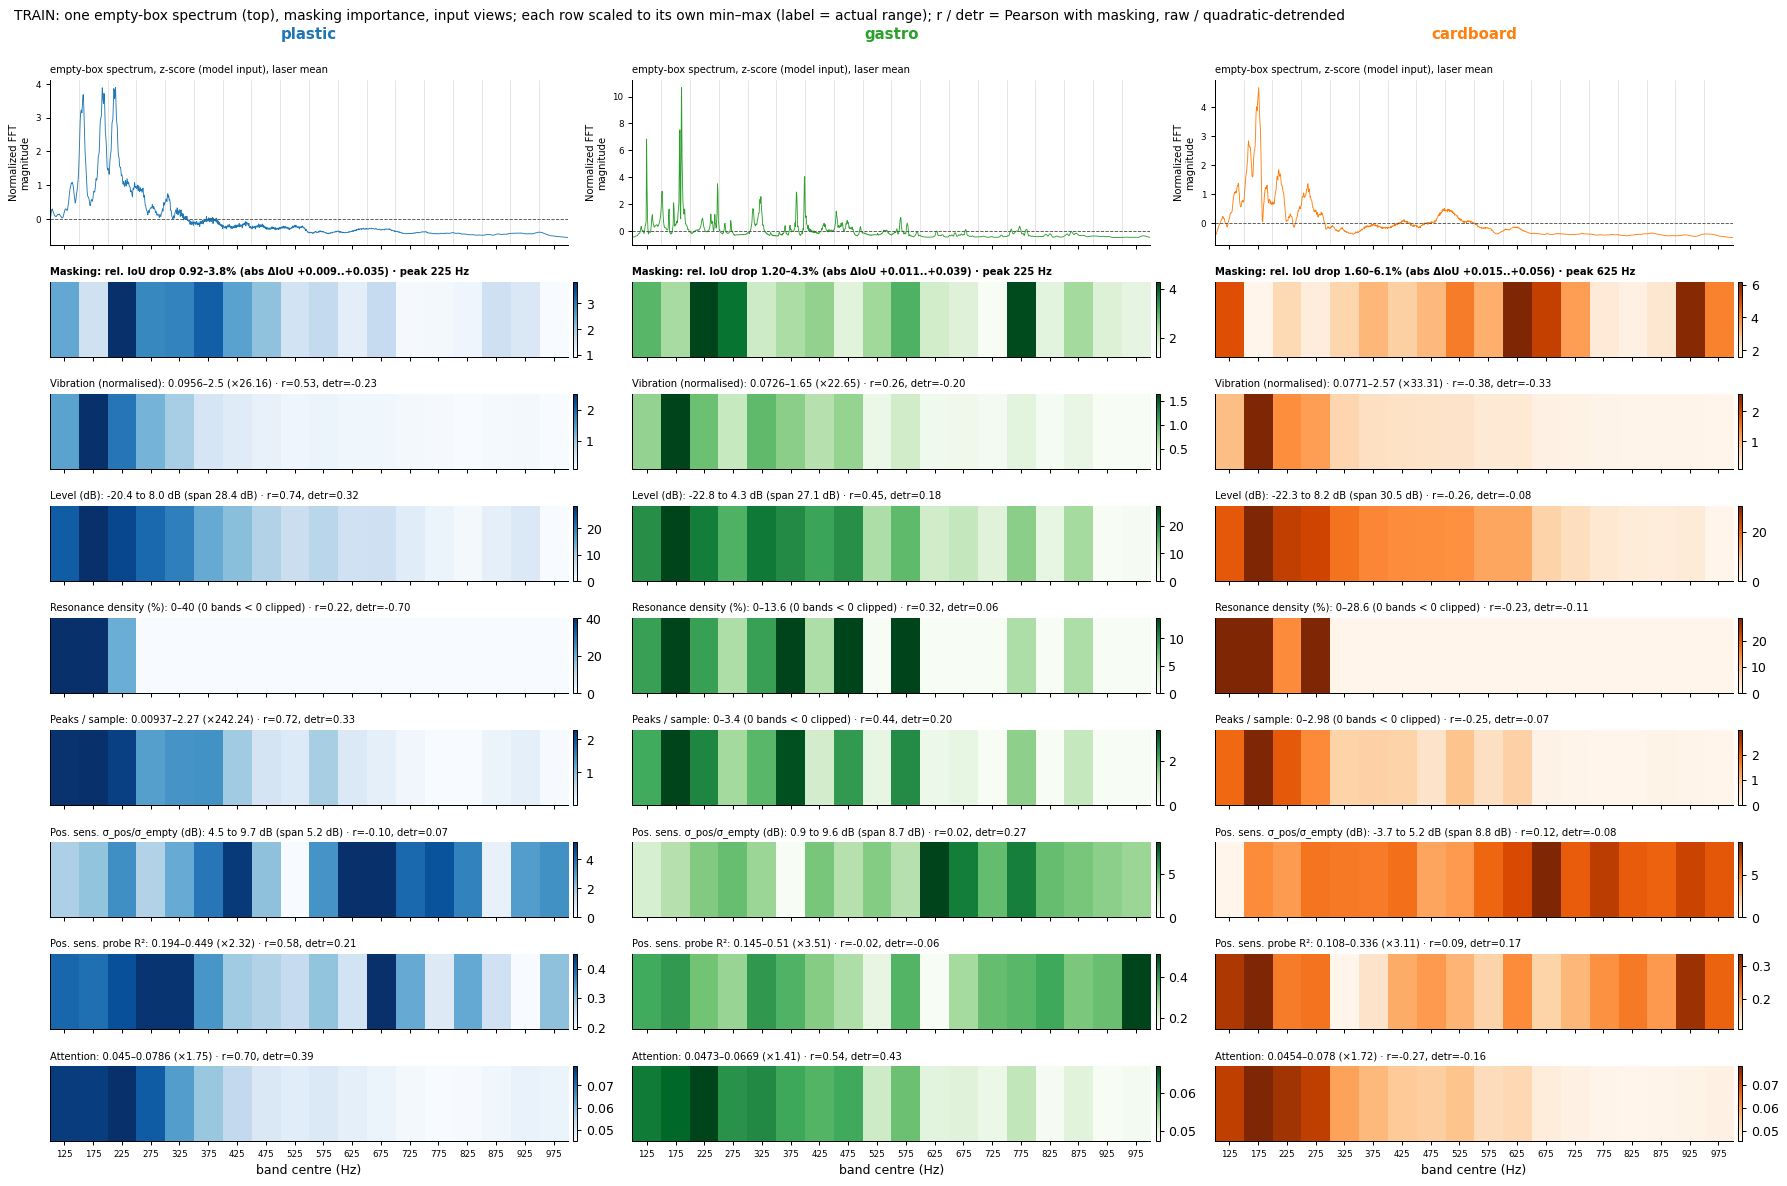

In [6]:
def figure(s):
    rows = ["Masking"] + VIEWS
    fig, ax = plt.subplots(len(rows) + 1, 3, figsize=(20, 1.3 * len(rows) + 3), gridspec_kw={"height_ratios": [2.2] + [1] * len(rows)})
    for j, b in enumerate(BX):   # top row: one empty-box capture, full resolution, x in heatmap-cell units (band k = cell k)
        a, e, xc = ax[0, j], ESPEC[b], (FHZ - 100) / 50 - .5
        a.plot(xc, e["z"], c=BOXC[b], lw=.7); a.axhline(0, c="0.3", lw=.7, ls="--")
        for k in range(19): a.axvline(k - .5, c="gray", lw=.4, alpha=.4)
        a.set_xlim(-.5, 17.5); a.set_xticks(range(18), []); a.set_ylabel("Normalized FFT\nmagnitude", fontsize=8); a.tick_params(labelsize=7)
        a.set_title("empty-box spectrum, z-score (model input), laser mean", fontsize=8, loc="left")
        a.text(.5, 1.25, b, transform=a.transAxes, ha="center", fontsize=12, fontweight="bold", color=BOXC[b])
        fig.colorbar(plt.cm.ScalarMappable(cmap=CMAP[b]), ax=a, fraction=.025, pad=.01).ax.set_visible(False)   # same width as the heat rows
    ax = ax[1:]
    for i, nm in enumerate(rows):
        for j, b in enumerate(BX):
            a = ax[i, j]; x = MASK[s, b] if nm == "Masking" else np.asarray(V[s, b][nm], float); lo, hi = x.min(), x.max()
            if nm == "Masking":
                heat(a, 100 * x, b); lab = f"rel. IoU drop {100 * lo:.2f}–{100 * hi:.1f}% (abs ΔIoU {ABS[s, b].min():+.3f}..{ABS[s, b].max():+.3f})" + (f", {(x < 0).sum()} bands < 0 clipped" if lo < 0 else "") + f" · peak {HZ[x.argmax()]:.0f} Hz"
            else:
                if nm in DB: heat(a, x - lo, b); lab = f"{lo:.1f} to {hi:.1f} dB (span {hi - lo:.1f} dB)"
                else: heat(a, x, b); lab = f"{lo:.3g}–{hi:.3g}" + (f" (×{hi / lo:.2f})" if lo > 0 else f" ({(x < 0).sum()} bands < 0 clipped)")
                r, rd = R[s, nm, b]; lab += f" · r={r:.2f}, detr={rd:.2f}"
            a.set_yticks([]); a.set_title(f"{nm}: {lab}", fontsize=8, loc="left", fontweight="bold" if nm == "Masking" else "normal")
            a.set_xticks(range(18), [f"{h:.0f}" for h in HZ] if i == len(rows) - 1 else [], fontsize=7)
    for j in range(3): ax[-1, j].set_xlabel("band centre (Hz)")
    fig.suptitle(f"{s.upper()}: one empty-box spectrum (top), masking importance, input views; each row scaled to its own min–max (label = actual range); r / detr = Pearson with masking, raw / quadratic-detrended",
                 x=.01, ha="left", fontsize=11)
    plt.tight_layout(); plt.show()
figure("train")

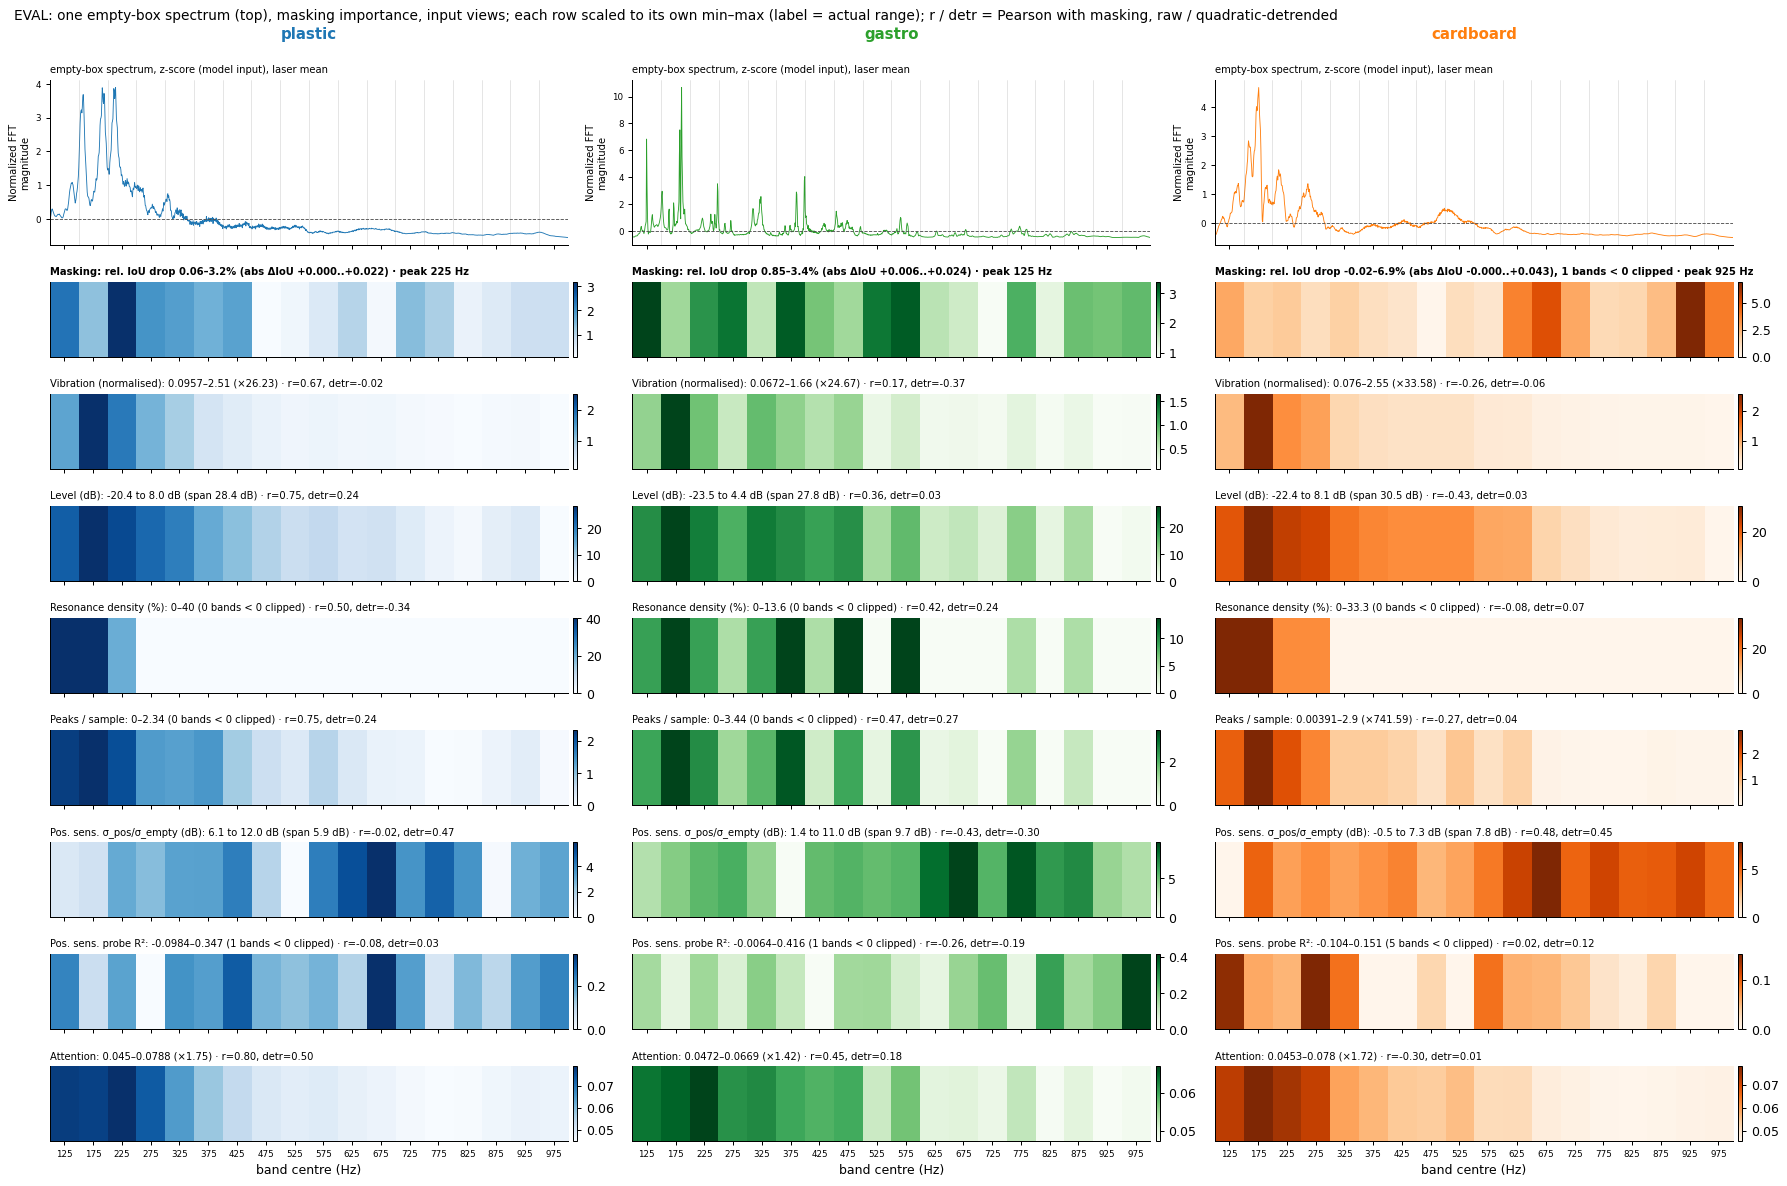

In [7]:
figure("eval")

## Empty-box spectrum with masking overlaid
The same single empty-box capture per box, one full-width row per box, **exactly as the model sees it**: the **normalized FFT magnitude**. Start from |X| (tukey window, as in `src9/dataset.py`), divided by its std (`process_x`). Then apply the encoder's per-sample z-score (`src9/arch/transformer4.py:138`: `x = (x - x.mean((1,2,3))) / (x.std((1,2,3)) + 1e-6)`): subtract the mean and divide by the unbiased std over lasers × bins × channels together, for that one capture, so the capture has mean 0 and std 1. Finally average over the 100 lasers and both channels. Linear units, no dB; the dashed line is 0 (the capture mean).
Each row shows the full spectrum: its y-axis runs from the min to the max with a 5% margin, nothing is clipped. Rows are tall so the part above 500 Hz stays readable.
Each 50 Hz band is coloured by that box's **masking ΔIoU** (absolute IoU drop, mean over the 240 samples):
- spectrum segment: thicker and darker with ΔIoU;
- small grey label above each band (above the axes): ΔIoU, with the top 3 in bold, in the box's dark shade.

Negative ΔIoU is drawn as 0. Colour scales are per box (box hue), so each row has its own slim colorbar.
**Dots** are the box's resonances from cell 5 (nb109 relaxed rule, the same `RES` that feeds the resonance-density view). They come from the **train** samples and are used in both figures. A dot is drawn at the spectrum value at that frequency.

In [4]:
from matplotlib.colors import to_rgb, LinearSegmentedColormap, Normalize
EDGES = 100 + 50 * np.arange(19)
def plot_fft_masking(ax, hz, spec, dIoU, color, label, res):
    c = np.array(to_rgb(color)); light, dark = .3 * c + .7, .5 * c
    cm = LinearSegmentedColormap.from_list("m", [light, dark]); d = np.clip(dIoU, 0, None); w = d / d.max(); top = np.argsort(-d)[:3]
    lo, hi = spec.min(), spec.max(); pad = .05 * (hi - lo)
    for k in range(18):
        m = (hz >= EDGES[k]) & (hz <= EDGES[k + 1])
        ax.plot(hz[m], spec[m], c=cm(w[k]), lw=.8 + 3.2 * w[k], solid_capstyle="butt")
        ax.text(EDGES[k] + 25, 1.01, f"{d[k]:.3f}".replace("0.", ".", 1), transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=7,
                color=dark if k in top else "0.45", fontweight="bold" if k in top else "normal")
    for e in EDGES: ax.axvline(e, c="0.6", lw=.25)
    ax.scatter(hz[res], spec[res], s=14, c="0.1", edgecolors="white", linewidths=.7, zorder=5, label="resonance (nb109 relaxed rule, train)")
    ax.axhline(0, c="0.3", lw=.7, ls="--")
    ax.set(xlim=(100, 1000), ylim=(lo - pad, hi + pad)); ax.grid(axis="y", lw=.4, alpha=.5); ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False); ax.tick_params(labelsize=8)
    ax.set_ylabel("Normalized FFT magnitude\n(z-score: mean 0, std 1 per sample)", fontsize=9)
    ax.set_title(label, loc="left", fontsize=13, fontweight="bold", color=color, pad=14)
    cb = plt.colorbar(plt.cm.ScalarMappable(Normalize(0, d.max()), cm), ax=ax, fraction=.012, pad=.008, aspect=12); cb.set_label("ΔIoU", fontsize=8); cb.ax.tick_params(labelsize=7); cb.outline.set_visible(False)
    return lo - pad, hi + pad
def fig_fft_masking(set_name):
    fig, ax = plt.subplots(3, 1, figsize=(22, 4 * 3), sharex=True, gridspec_kw={"hspace": .22})
    for a, b in zip(ax, BX):
        y0, y1 = plot_fft_masking(a, FHZ, ESPEC[b]["z"], ABS[set_name, b], BOXC[b], b, RES["train", b])
        print(f"{b}: {len(RES['train', b])} resonances dotted, y-range {y0:.2f} .. {y1:.2f}")
    fig.legend(*ax[0].get_legend_handles_labels(), loc="upper right", bbox_to_anchor=(.9, .955), fontsize=8, frameon=False)
    for a in ax[:-1]: a.tick_params(labelbottom=False)
    ax[-1].set_xticks(EDGES[:-1] + 25, [f"{h}" for h in EDGES[:-1] + 25]); ax[-1].set_xlabel("band centre (Hz)", fontsize=9)
    fig.suptitle(f"Empty-box spectrum (normalized FFT magnitude = model input z-score, laser mean) coloured by {set_name.upper()} masking ΔIoU per 50 Hz band", x=.06, ha="left", fontsize=12, y=.955)
    plt.show()

### Train masking

plastic: 5 resonances dotted, y-range -0.78 .. 4.11
gastro: 22 resonances dotted, y-range -1.03 .. 11.23
cardboard: 7 resonances dotted, y-range -0.75 .. 4.92


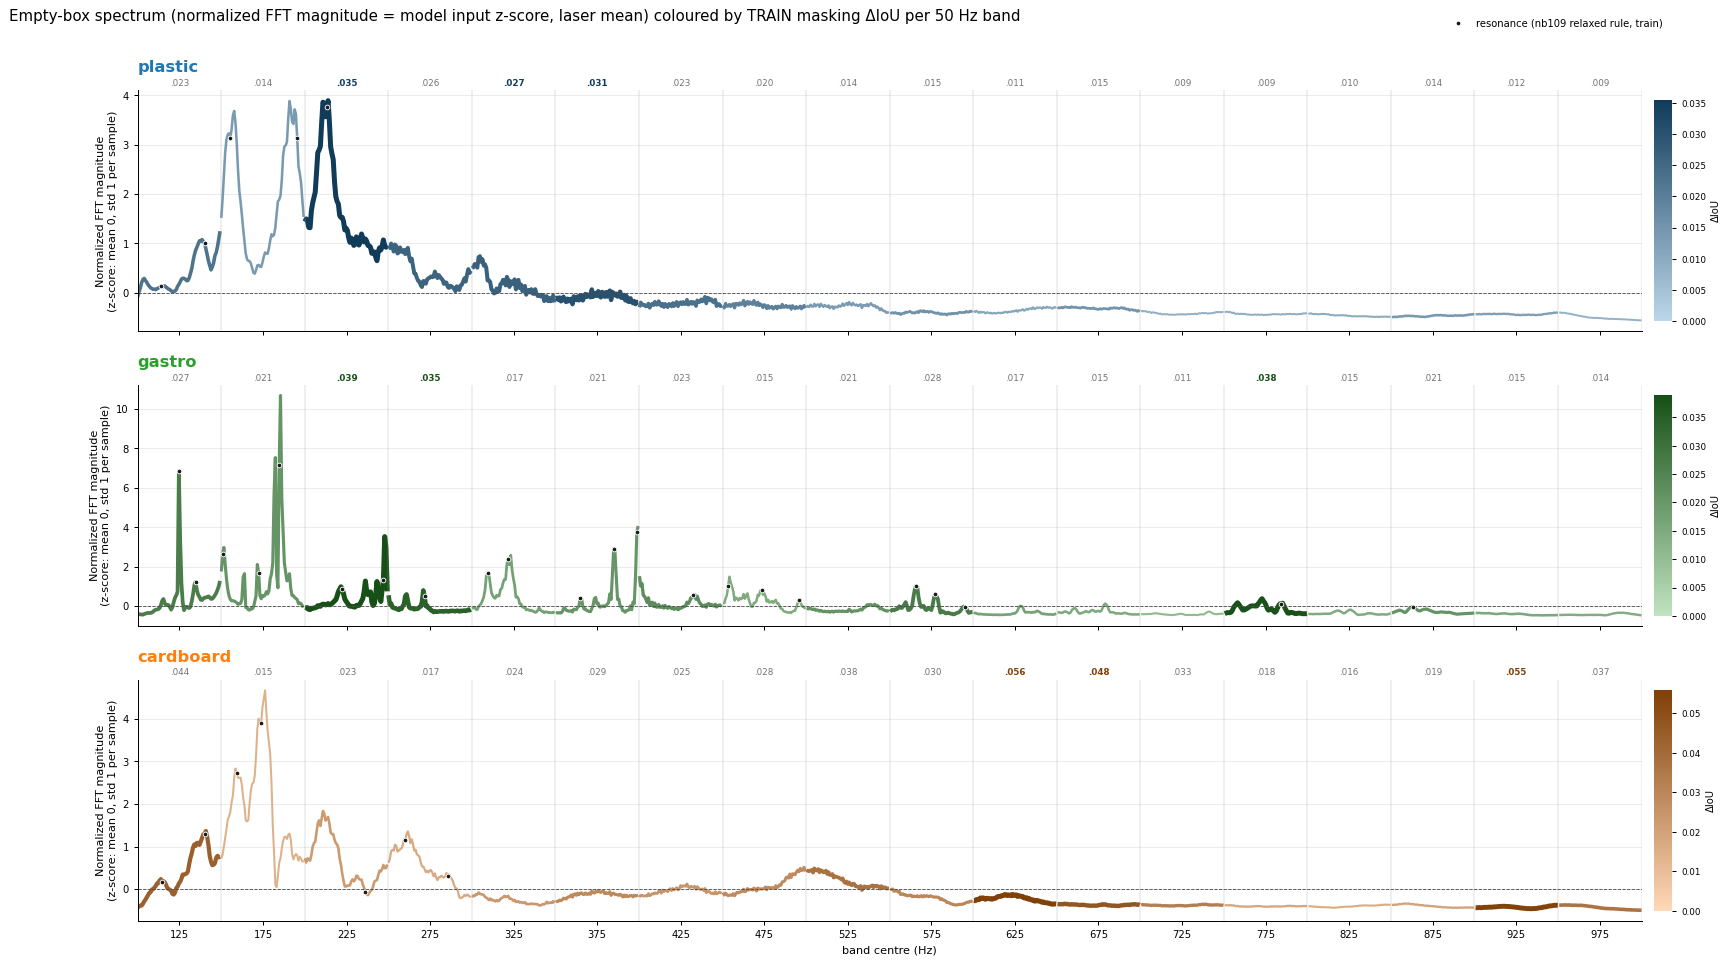

In [9]:
fig_fft_masking("train")

### Eval masking

plastic: 5 resonances dotted, y-range -0.78 .. 4.11
gastro: 22 resonances dotted, y-range -1.03 .. 11.23
cardboard: 7 resonances dotted, y-range -0.75 .. 4.92


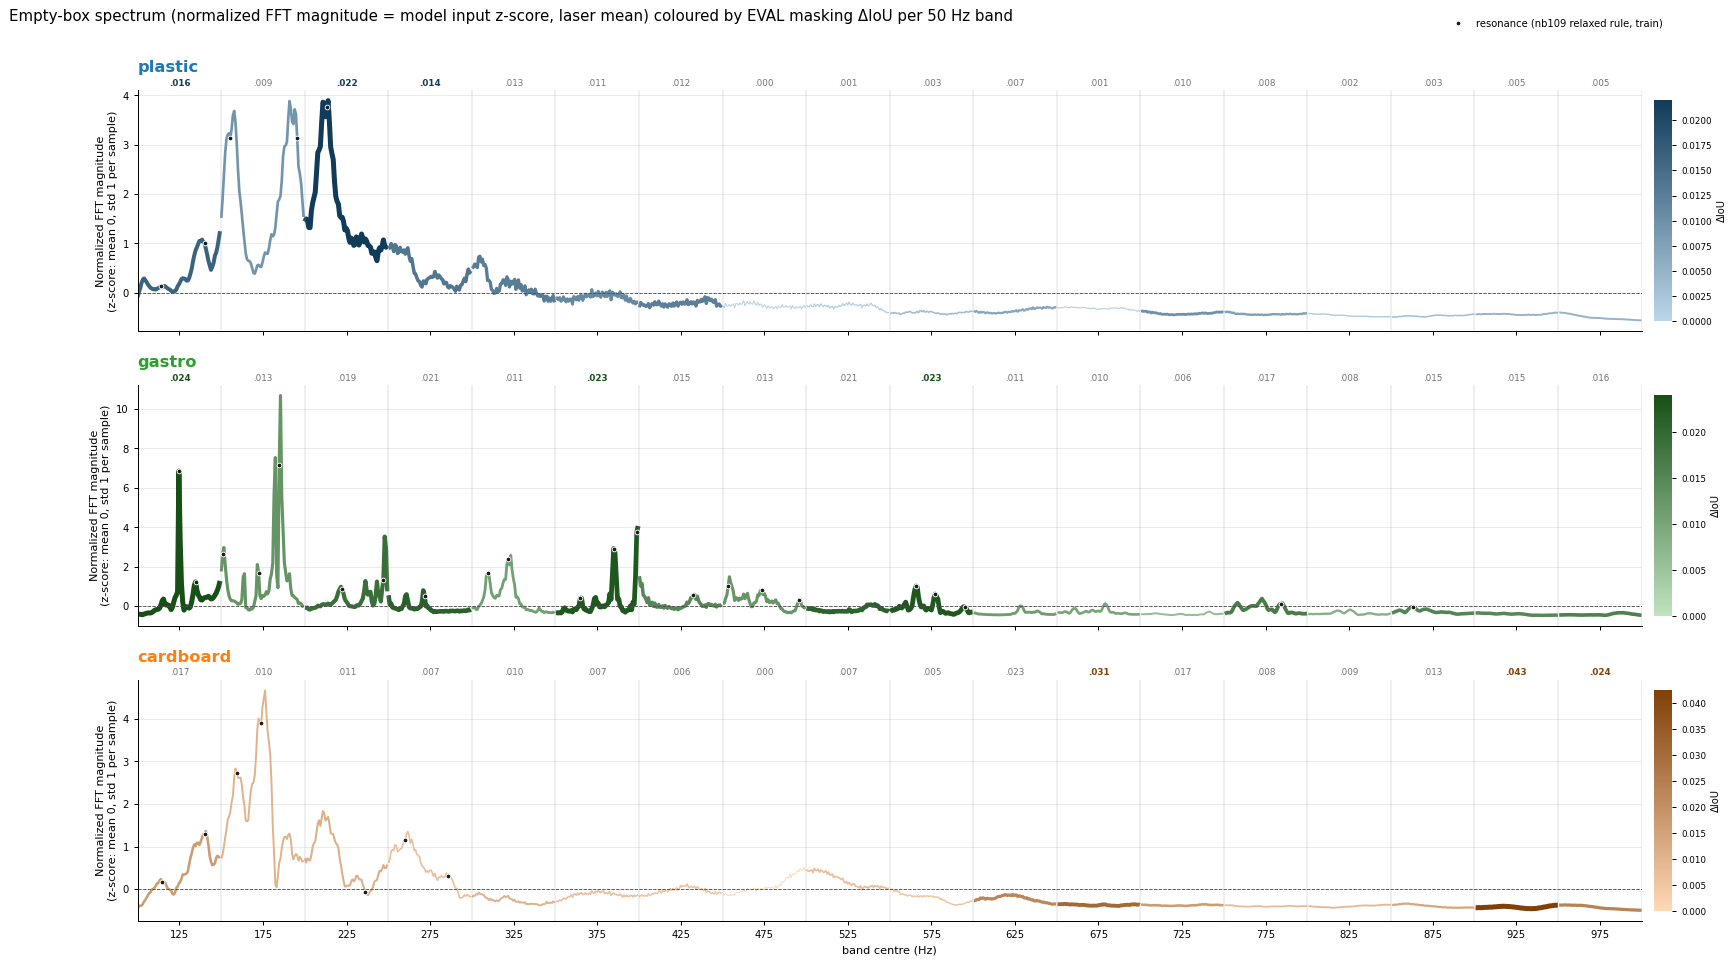

In [10]:
fig_fft_masking("eval")

### r with masking, per (set, view, box)
`raw (detr)`. Last column: masking itself between train and eval for the same box (does the model use the same bands on held-out positions?).

In [11]:
T = pd.DataFrame({(s, b): {nm: f"{R[s, nm, b][0]:+.2f} ({R[s, nm, b][1]:+.2f})" for nm in VIEWS} for s in SETS for b in BX})
print(T.to_string())
print("\nmasking train vs eval, same box:", {b: "%+.2f (%+.2f)" % r2(MASK["train", b], MASK["eval", b]) for b in BX})
print("masking between boxes:", {f"{s}:{p}~{c}": "%+.2f (%+.2f)" % r2(MASK[s, p], MASK[s, c]) for s in SETS for i, p in enumerate(BX) for c in BX[i + 1:]})

                                       train                                         eval                              
                                     plastic         gastro      cardboard        plastic         gastro      cardboard
Vibration (normalised)         +0.53 (-0.23)  +0.26 (-0.20)  -0.38 (-0.33)  +0.67 (-0.02)  +0.17 (-0.37)  -0.26 (-0.06)
Level (dB)                     +0.74 (+0.32)  +0.45 (+0.18)  -0.26 (-0.08)  +0.75 (+0.24)  +0.36 (+0.03)  -0.43 (+0.03)
Resonance density (%)          +0.22 (-0.70)  +0.32 (+0.06)  -0.23 (-0.11)  +0.50 (-0.34)  +0.42 (+0.24)  -0.08 (+0.07)
Peaks / sample                 +0.72 (+0.33)  +0.44 (+0.20)  -0.25 (-0.07)  +0.75 (+0.24)  +0.47 (+0.27)  -0.27 (+0.04)
Pos. sens. σ_pos/σ_empty (dB)  -0.10 (+0.07)  +0.02 (+0.27)  +0.12 (-0.08)  -0.02 (+0.47)  -0.43 (-0.30)  +0.48 (+0.45)
Pos. sens. probe R²            +0.58 (+0.21)  -0.02 (-0.06)  +0.09 (+0.17)  -0.08 (+0.03)  -0.26 (-0.19)  +0.02 (+0.12)
Attention                      +0.70 (+0

### TRAIN: r with masking per view, as bars
Left: raw Pearson r; right: after removing a quadratic in frequency from both curves. Dashed lines at ±.47 ≈ p .05 for n = 18 (two-sided); bands are not independent, so even that is optimistic.

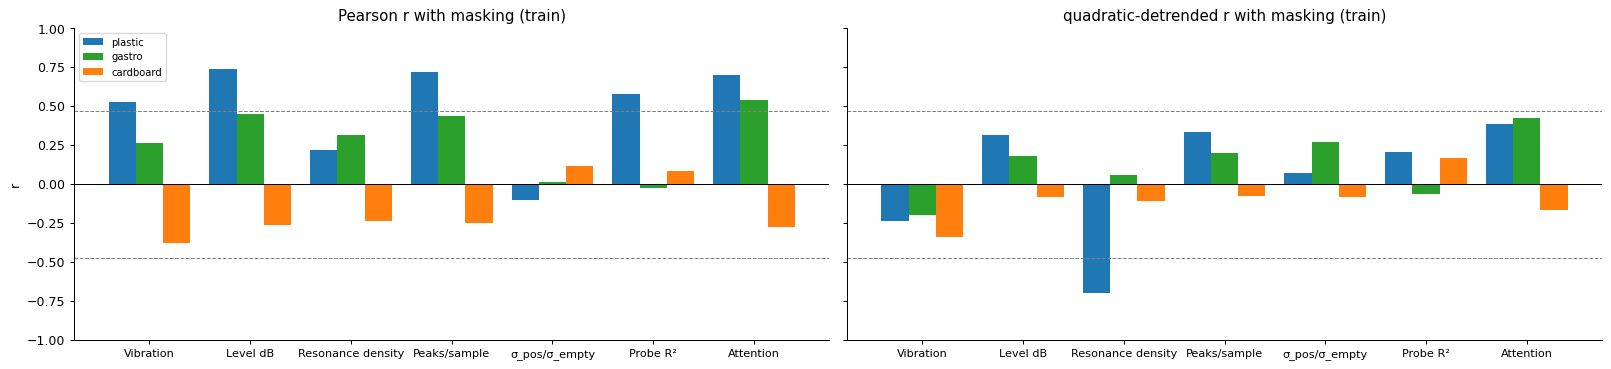

In [12]:
NM = ["Vibration", "Level dB", "Resonance density", "Peaks/sample", "σ_pos/σ_empty", "Probe R²", "Attention"]
fig, ax = plt.subplots(1, 2, figsize=(18, 4.2), sharey=True); w = .27
for a, k, t in zip(ax, (0, 1), ("Pearson r with masking (train)", "quadratic-detrended r with masking (train)")):
    for j, b in enumerate(BX): a.bar(np.arange(len(VIEWS)) + (j - 1) * w, [R["train", nm, b][k] for nm in VIEWS], w, color=BOXC[b], label=b)
    a.axhline(0, c="k", lw=.8); [a.axhline(y, c="gray", ls="--", lw=.8) for y in (-.47, .47)]
    a.set_xticks(range(len(VIEWS)), NM, fontsize=9); a.set_title(t); a.set_ylim(-1, 1)
ax[0].set_ylabel("r"); ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

### Summary
- **Masking is spread out.** No single band costs more than 3.8 / 4.3 / 6.1% of clean IoU on train (plastic / gastro / cardboard), 3.2 / 3.4 / 6.9% on eval. Peak bands: train 225 / 225 / 625 Hz, eval 225 / 125 / 925 Hz. Cardboard uses the high bands (600–975 Hz) on both sets; plastic uses the low bands.
- **Masking is stable across sets** (same box, train vs eval: r .71 / .64 / .74, detrended .49 / .56 / .82), but differs between boxes (cardboard vs the others: r −.13 to −.39).
- **Loudness views (vibration, level, peaks/sample, attention) follow masking only where use is loud.** In plastic raw r is .53–.80, but it drops to −.23 to +.50 after detrending. In gastro it is weak. In cardboard it is negative on both sets (−.26 to −.43 raw, ≈ 0 detrended). Attention is a loudness view, not a use view.
- **Resonance density** is concentrated below ~400 Hz in plastic and cardboard (5–7 resonances, all ≤ 285 Hz). It cannot explain cardboard's high-band use.
- **Position sensitivity (fixed definitions)** is inconsistent. σ_pos/σ_empty: train r −.10 / +.02 / +.12, eval −.02 / −.43 / **+.48 (detr +.45)**. Eval cardboard is the only view with a positive detrended r in that box, but its σ_empty comes from train empties, and it does not hold on train. Probe R²: train .58 / −.02 / .09, eval ≈ 0. Per-band position information in the raw input does not explain which bands the model uses.
- **Empty-box spectra** (one capture per box, spk 1; see also the overlay figures). Plastic and cardboard are smooth, while gastro has many narrow resonances. In cardboard, the masking peaks (625–675 and 875–975 Hz) do not sit on a loud feature. The broad hump is at ~500–575 Hz (−3 to −5 dB band mean), 625–675 Hz is ~6–8 dB below it, and 925 Hz (−21 dB) is near a small bump just before the roll-off. The empty-box spectrum does not show where cardboard is used.
- With n = 18 and one shared fall-off, |r| ≲ .5 is not distinguishable from noise (p ≈ .05 at |r| = .47). Most raw r values that look good shrink after quadratic detrending.

## Paper figure: spectral salience vs where the model looks
Four variations of one figure. All of them share the following:
- **Rows:** plastic / gastro / cardboard. Everything is linear: no dB, no log ratios.
- **Spectrum:** mean over **all train empty-box captures** of that box (60 / 36 / 73), with a shaded band of ±1 std **across captures**. Per capture, |X| uses the tukey window (`load_fft`) and is averaged over lasers and channels at full bin resolution. The cache is `runs/_src9_cache/nb138/empties_train.npz`.
- **Masking:** TRAIN per-band mean ΔIoU (240 samples per box, `q1_train.npz`), with a bootstrap 95% CI over samples drawn as thin error ticks.
- **Black ticks on the x baseline:** the box's train resonances (`RES`, nb109 relaxed rule).

In [5]:
EF = ROOT / "runs/_src9_cache/nb138/empties_train.npz"
if not EF.exists():   # needs cell 7 (PATHS, METAS, BI); streams one capture at a time
    sp, sg, bx = [], [], []
    for j, b in zip(Q["train"]["emp"], Q["train"]["emp_box"]):
        i = int(BI[int(j)]); x = load_fft(PATHS[i], METAS[i], "tukey").abs().numpy(); sp.append(x.mean((0, 2))); sg.append(x.std(ddof=1)); bx.append(b)
    EF.parent.mkdir(parents=True, exist_ok=True); np.savez(EF, spec=np.array(sp), sig=np.array(sg), box=np.array(bx))
E = np.load(EF); eb = E["box"]
SPEC = {b: {"norm": E["spec"][eb == b] / E["sig"][eb == b, None],                                   # |X| / σ_sample (model's first normalisation)
            "frac": E["spec"][eb == b] / E["spec"][eb == b].sum(1, keepdims=True),                 # ÷ total over bins
            "raw": E["spec"][eb == b]} for b in BX}
print({b: len(SPEC[b]["raw"]) for b in BX}, "train empty captures")
BC, rng = 100 + 50 * np.arange(18) + 25, np.random.default_rng(0)   # band centres for drawing (bands are 65 bins ≈ 50 Hz)
share = lambda m: np.clip(m, 0, None) / np.clip(m, 0, None).sum()
def boot(b, f=lambda m: m, n=1000):   # (f(mean ΔIoU), 95% CI) bootstrapped over the box's train samples
    d = Q["train"]["mask_b"][Q["train"]["box"] == b].astype(float); k = rng.integers(0, len(d), (n, len(d)))
    return f(d.mean(0)), np.percentile([f(d[i].mean(0)) for i in k], [2.5, 97.5], 0)
dark = lambda b: .6 * np.array(to_rgb(BOXC[b]))
def row(a, b, last):   # shared row styling: title, resonance ticks, spines, x range
    a.set_title(b, loc="left", fontsize=11, fontweight="bold", color=BOXC[b])
    a.plot(FHZ[RES["train", b]], np.zeros(len(RES["train", b])), "|", c="k", ms=7, mew=1, transform=a.get_xaxis_transform(), clip_on=False, zorder=6)
    a.spines["top"].set_visible(False); a.set_xlim(100, 1000); a.tick_params(labelsize=8)
    if last: a.set_xticks(BC[::2], [f"{h}" for h in BC[::2]]); a.set_xlabel("frequency (Hz)", fontsize=9)
def fig_spec_bars(kind, ylab, title):   # V1 / V3 / V4: spectrum (left axis) over masking bars (right axis, background)
    fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
    for n, (a, b) in enumerate(zip(ax, BX)):
        mu, sd = SPEC[b][kind].mean(0), SPEC[b][kind].std(0); m, ci = boot(b)
        t = a.twinx(); a.set_zorder(t.get_zorder() + 1); a.patch.set_visible(False)
        t.bar(BC, m, 44, color=BOXC[b], alpha=.22, lw=0)
        t.errorbar(BC, m, yerr=[m - ci[0], ci[1] - m], fmt="none", ecolor=BOXC[b], elinewidth=.8, capsize=2, alpha=.9)
        t.set_ylim(0, 1.1 * ci[1].max()); t.set_ylabel("ΔIoU when band masked", fontsize=9, color=BOXC[b]); t.tick_params(labelsize=8); t.spines["top"].set_visible(False)
        a.fill_between(FHZ, mu - sd, mu + sd, color=dark(b), alpha=.25, lw=0); a.plot(FHZ, mu, c=dark(b), lw=.9)
        a.set_ylim(0, 1.05 * (mu + sd).max()); a.set_ylabel(ylab, fontsize=9); row(a, b, n == 2)
    fig.suptitle(title, x=.01, ha="left", fontsize=11); plt.tight_layout(); plt.show()

{'plastic': 60, 'gastro': 36, 'cardboard': 73} train empty captures


### V1: spectrum |X|/σ_sample (left) over masking ΔIoU bars (right)

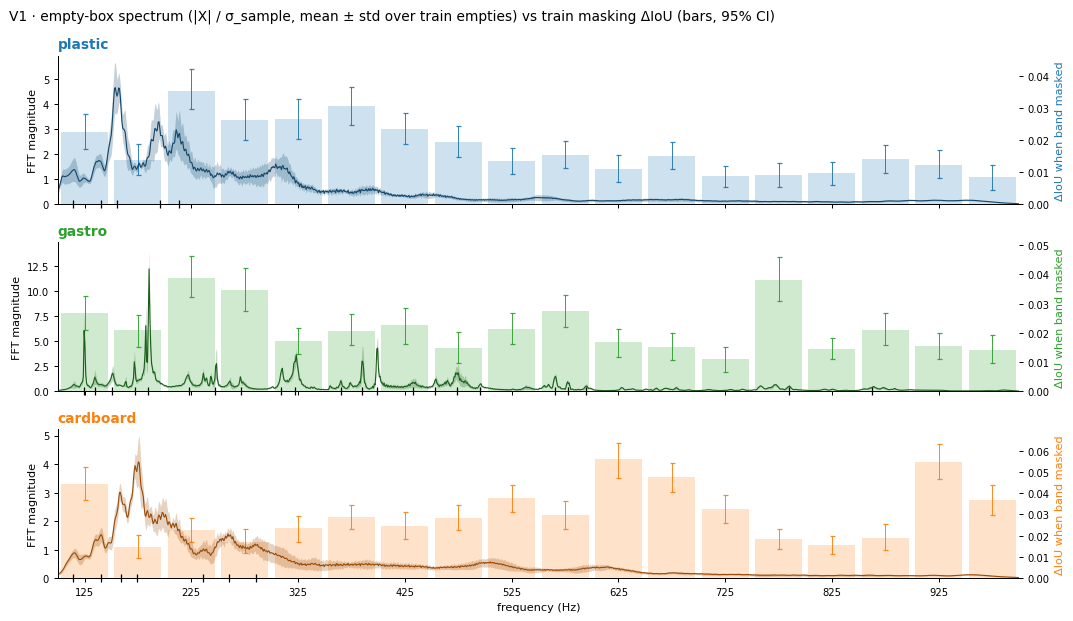

In [14]:
fig_spec_bars("norm", "FFT magnitude", "V1 · empty-box spectrum (|X| / σ_sample, mean ± std over train empties) vs train masking ΔIoU (bars, 95% CI)")

### V2: energy share vs importance share, one axis

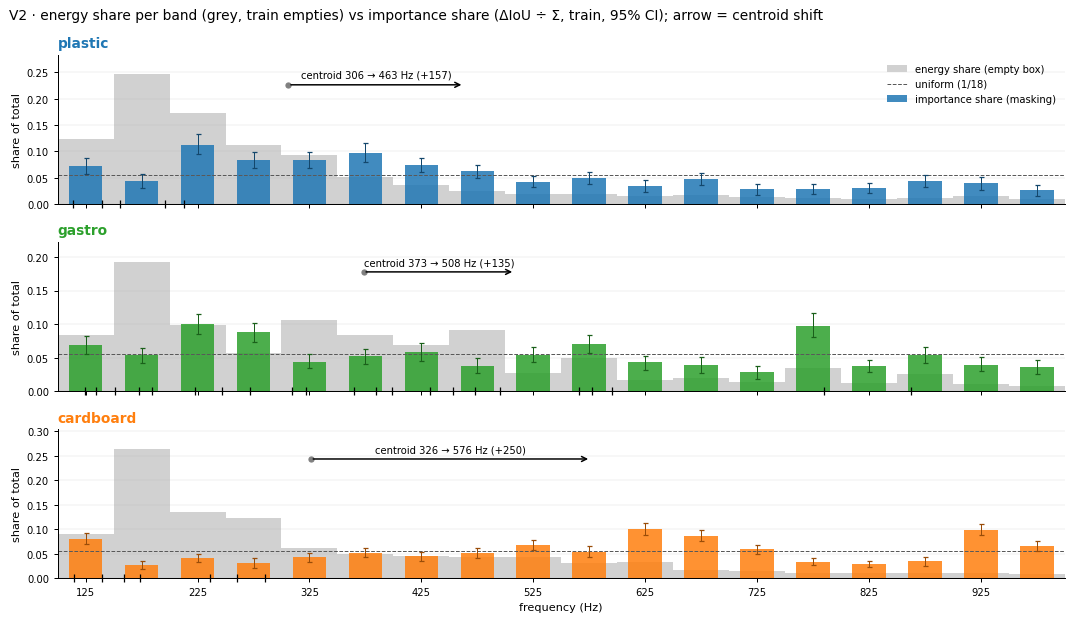

centroid energy → importance (Hz): {'plastic': '306 → 463 (+157)', 'gastro': '373 → 508 (+135)', 'cardboard': '326 → 576 (+250)'}


In [15]:
def fig_shares():
    fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True); SH = {}
    for n, (a, b) in enumerate(zip(ax, BX)):
        s = SPEC[b]["norm"].mean(0); e = np.array([s[BIN == k].sum() for k in range(18)]); e = e / e.sum()
        m, ci = boot(b, share)
        a.stairs(e, 100 + 50 * np.arange(19), fill=True, color="0.82", label="energy share (empty box)", zorder=1)
        a.bar(BC, m, 30, color=BOXC[b], alpha=.85, lw=0, label="importance share (masking)", zorder=2)
        a.errorbar(BC, m, yerr=[m - ci[0], ci[1] - m], fmt="none", ecolor=dark(b), elinewidth=.8, capsize=2, zorder=3)
        a.axhline(1 / 18, ls="--", c="0.35", lw=.8, label="uniform (1/18)")
        ce, cm_ = (e * HZ).sum(), (m * HZ).sum(); SH[b] = (ce, cm_); y = .92 * max(e.max(), ci[1].max())
        a.annotate("", xy=(cm_, y), xytext=(ce, y), arrowprops=dict(arrowstyle="->", color="k", lw=1.2))
        a.plot([ce], [y], "o", c="0.5", ms=4); a.text((ce + cm_) / 2, 1.04 * y, f"centroid {ce:.0f} → {cm_:.0f} Hz ({cm_ - ce:+.0f})", ha="center", va="bottom", fontsize=8)
        a.set_ylim(0, 1.15 * max(e.max(), ci[1].max())); a.set_ylabel("share of total", fontsize=9); a.grid(axis="y", lw=.3, alpha=.5); row(a, b, n == 2)
    ax[0].legend(fontsize=8, frameon=False, loc="upper right")
    fig.suptitle("V2 · energy share per band (grey, train empties) vs importance share (ΔIoU ÷ Σ, train, 95% CI); arrow = centroid shift", x=.01, ha="left", fontsize=11)
    plt.tight_layout(); plt.show()
    print("centroid energy → importance (Hz):", {b: f"{c0:.0f} → {c1:.0f} ({c1 - c0:+.0f})" for b, (c0, c1) in SH.items()})
fig_shares()

### V3: spectrum ÷ total energy (left) over masking ΔIoU bars (right)

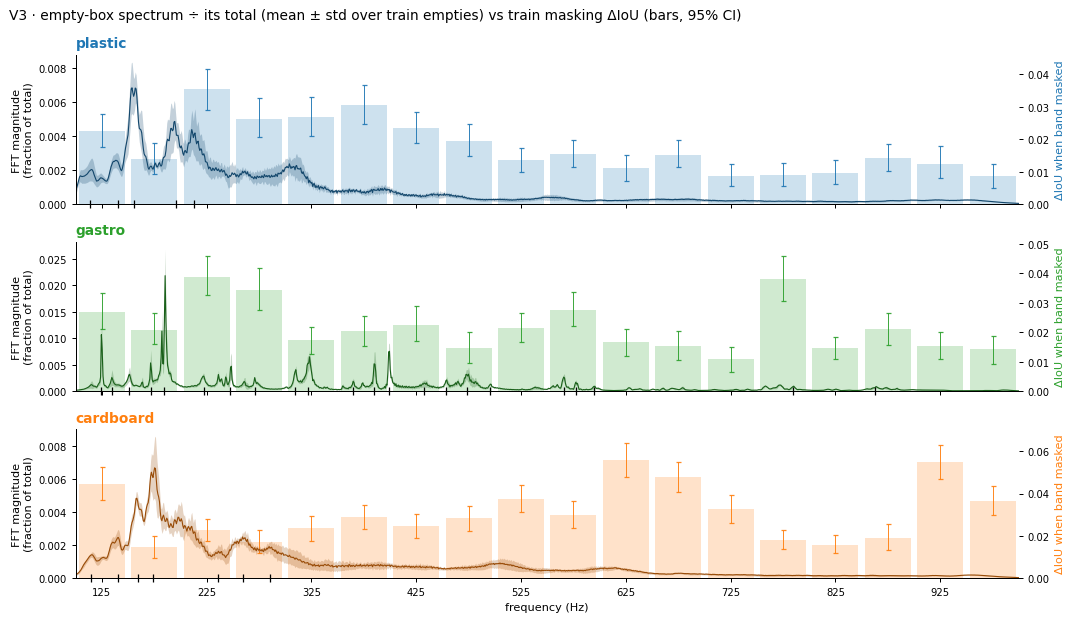

In [16]:
fig_spec_bars("frac", "FFT magnitude\n(fraction of total)", "V3 · empty-box spectrum ÷ its total (mean ± std over train empties) vs train masking ΔIoU (bars, 95% CI)")

### V4: raw |X| spectrum (left) over masking ΔIoU bars (right)

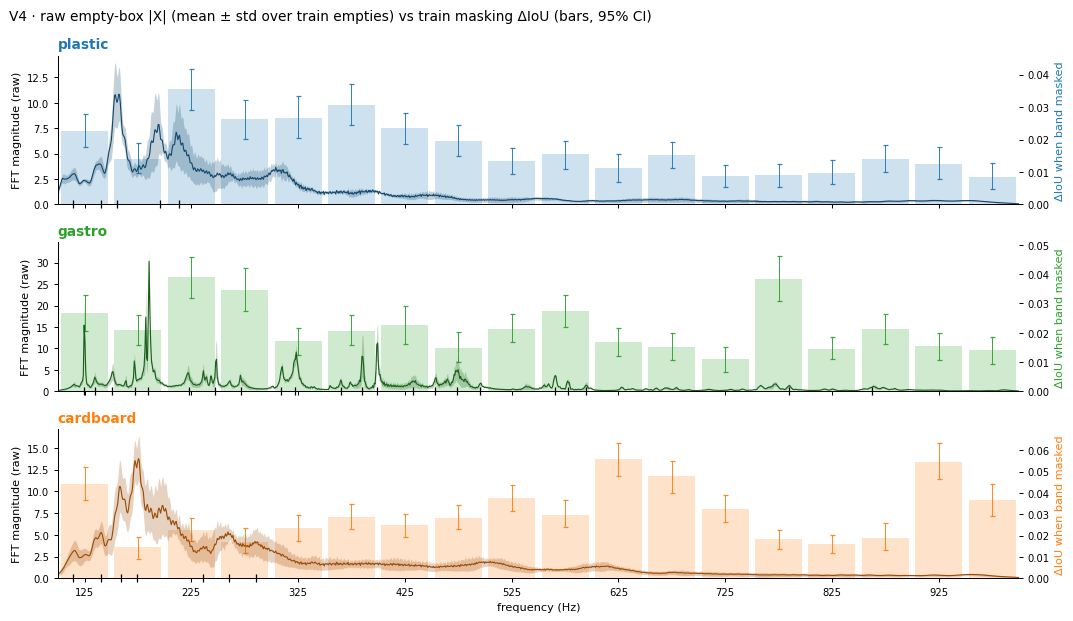

In [17]:
fig_spec_bars("raw", "FFT magnitude (raw)", "V4 · raw empty-box |X| (mean ± std over train empties) vs train masking ΔIoU (bars, 95% CI)")

### V5: model-input spectrum (z-score, left) over masking ΔIoU bars with values (right)

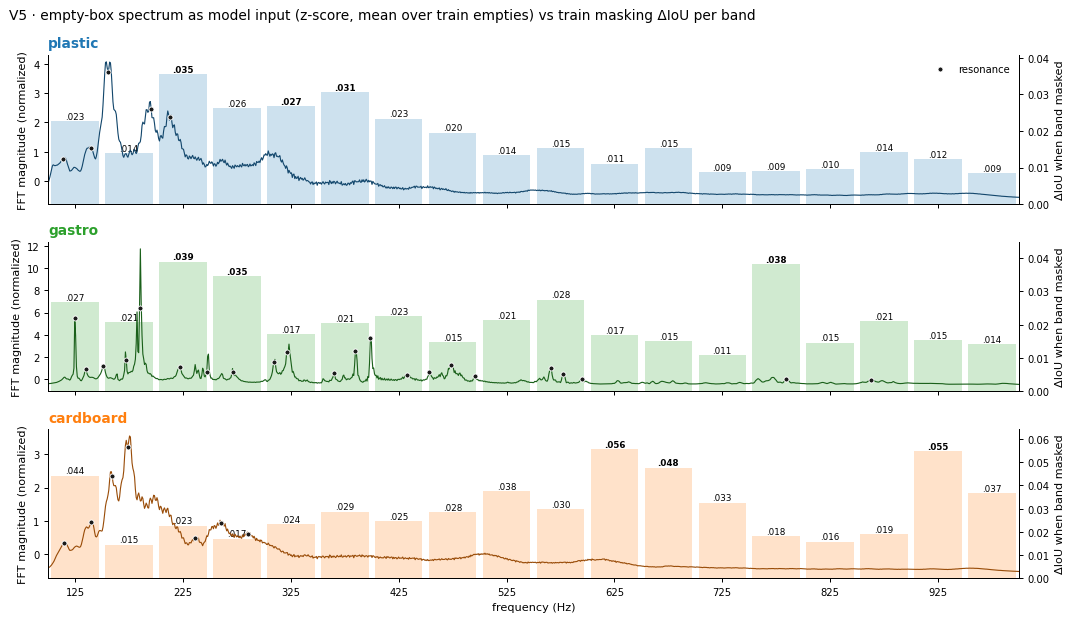

In [6]:
# exact from the cache: per capture v = |X|/σ (σ unbiased) has std 1, so z = (v - mean v) / (1 + 1e-6); the full-tensor mean of v = mean of the laser/channel-mean spectrum / σ (equal counts)
ZS = {b: ((E["spec"][eb == b] - E["spec"][eb == b].mean(1, keepdims=True)) / E["sig"][eb == b, None] / (1 + 1e-6)).mean(0) for b in BX}
def fig_v5():
    fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
    for n, (a, b) in enumerate(zip(ax, BX)):
        z, m = ZS[b], Q["train"]["mask_b"][Q["train"]["box"] == b].mean(0); top = np.argsort(-m)[:3]
        t = a.twinx(); a.set_zorder(t.get_zorder() + 1); a.patch.set_visible(False)
        t.bar(BC, m, 44, color=BOXC[b], alpha=.22, lw=0)
        for k in range(18): t.text(BC[k], m[k], f"{m[k]:.3f}".replace("0.", ".", 1), ha="center", va="bottom", fontsize=7, fontweight="bold" if k in top else "normal")
        t.set_ylim(0, 1.15 * m.max()); t.set_ylabel("ΔIoU when band masked", fontsize=9, color="k"); t.tick_params(labelsize=8, colors="k")
        t.spines["right"].set_visible(True); t.spines["right"].set_color("k"); t.spines["top"].set_visible(False)
        a.plot(FHZ, z, c=dark(b), lw=.9)
        r = RES["train", b]; a.scatter(FHZ[r], z[r], s=16, c="0.1", edgecolors="white", linewidths=.7, zorder=5, label="resonance")
        a.set_ylim(z.min() - .05 * np.ptp(z), z.max() + .05 * np.ptp(z)); a.set_ylabel("FFT magnitude (normalized)", fontsize=9)
        a.set_title(b, loc="left", fontsize=11, fontweight="bold", color=BOXC[b]); a.spines["top"].set_visible(False); a.set_xlim(100, 1000); a.tick_params(labelsize=8)
        if n == 2: a.set_xticks(BC[::2], [f"{h}" for h in BC[::2]]); a.set_xlabel("frequency (Hz)", fontsize=9)
    ax[0].legend(fontsize=8, frameon=False, loc="upper right")
    fig.suptitle("V5 · empty-box spectrum as model input (z-score, mean over train empties) vs train masking ΔIoU per band", x=.01, ha="left", fontsize=11)
    plt.tight_layout(); plt.show()
fig_v5()

### V6: grey + accents (V5 layout): warm = 3 loudest bands, box colour = 3 most important bands

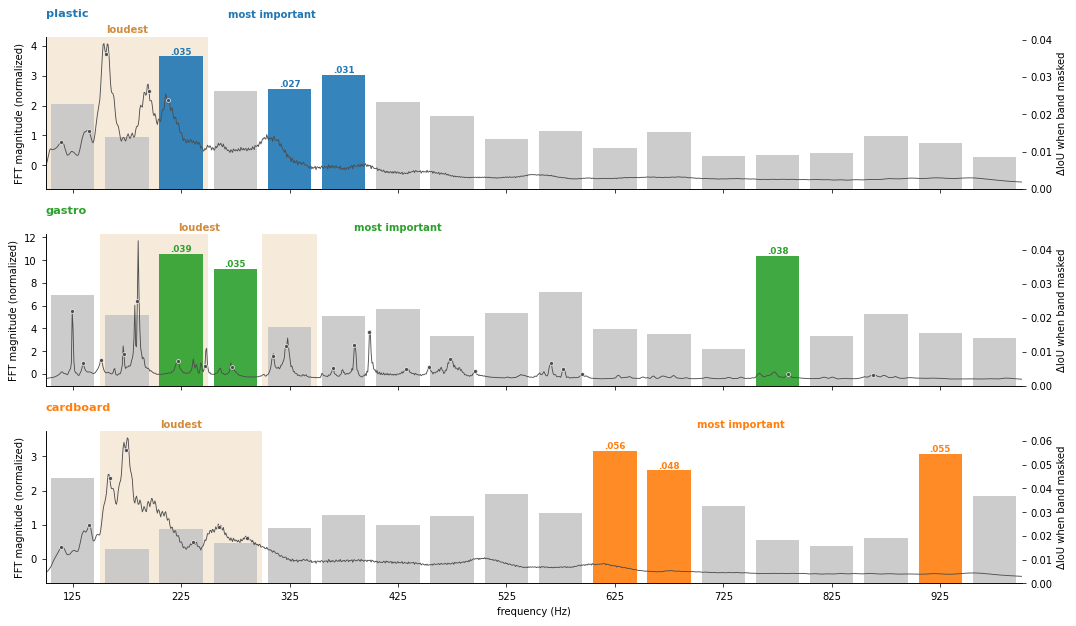

In [7]:
WARM, GREY = "#d08c3c", "0.78"
M5 = {b: Q["train"]["mask_b"][Q["train"]["box"] == b].mean(0) for b in BX}                       # train ΔIoU per band
BZ = {b: np.array([ZS[b][BIN == k].mean() for k in range(18)]) for b in BX}                      # mean z per band
LOUD, TOP = {b: np.argsort(-BZ[b])[:3] for b in BX}, {b: np.argsort(-M5[b])[:3] for b in BX}
fmt = lambda v: f"{v:.3f}".replace("0.", ".", 1)
PAPER = {"font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8, "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.linewidth": .6, "xtick.major.width": .6, "ytick.major.width": .6}
def xaxis(a, last):
    a.set_xlim(100, 1000)
    if last: a.set_xticks(BC[::2], [f"{h}" for h in BC[::2]]); a.set_xlabel("frequency (Hz)")
    else: a.tick_params(labelbottom=False)
def group_labels(a, b):   # "loudest" / "most important" above each group, raised if they would collide
    xl, xt = BC[LOUD[b]].mean(), BC[TOP[b]].mean(); dy = .1 if abs(xl - xt) < 140 else 0
    a.text(xl, 1.01, "loudest", transform=a.get_xaxis_transform(), ha="center", va="bottom", color=WARM, fontweight="bold")
    a.text(xt, 1.01 + dy, "most important", transform=a.get_xaxis_transform(), ha="center", va="bottom", color=BOXC[b], fontweight="bold")
def fig_v6():
    with plt.rc_context(PAPER):
        fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
        for n, (a, b) in enumerate(zip(ax, BX)):
            z, m = ZS[b], M5[b]; t = a.twinx(); a.set_zorder(t.get_zorder() + 1); a.patch.set_visible(False)
            for k in LOUD[b]: t.axvspan(BC[k] - 25, BC[k] + 25, color=WARM, alpha=.18, lw=0)
            t.bar(BC, m, 40, color=[BOXC[b] if k in TOP[b] else GREY for k in range(18)], alpha=.9, lw=0)
            for k in TOP[b]: t.text(BC[k], m[k], fmt(m[k]), ha="center", va="bottom", fontsize=7, fontweight="bold", color=BOXC[b])
            t.set_ylim(0, 1.15 * m.max()); t.set_ylabel("ΔIoU when band masked"); t.spines["top"].set_visible(False); t.spines["right"].set_color("k")
            a.plot(FHZ, z, c="0.3", lw=.7); r = RES["train", b]; a.scatter(FHZ[r], z[r], s=10, c="0.3", edgecolors="white", linewidths=.5, zorder=5)
            a.set_ylim(z.min() - .05 * np.ptp(z), z.max() + .05 * np.ptp(z)); a.set_ylabel("FFT magnitude (normalized)"); a.spines["top"].set_visible(False)
            a.set_title(b, loc="left", fontweight="bold", color=BOXC[b], pad=16); group_labels(a, b); xaxis(a, n == 2)
        plt.tight_layout(); plt.show()
fig_v6()

### V7: spectrum as soft area, ΔIoU as lollipops, arrow from spectral peak to most important band

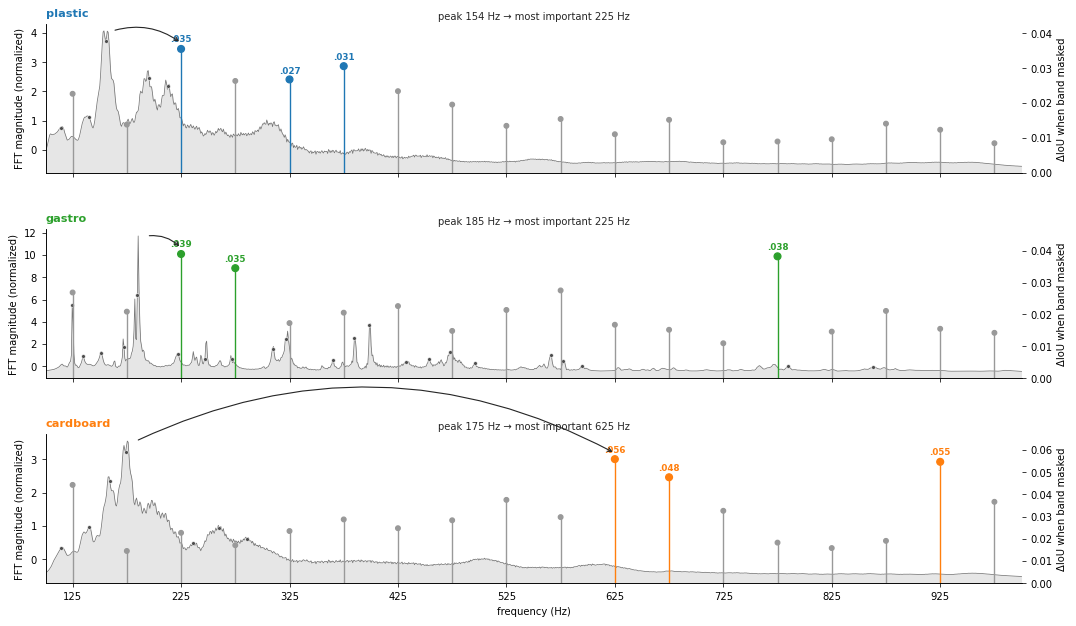

In [20]:
def fig_v7():
    with plt.rc_context(PAPER):
        fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
        for n, (a, b) in enumerate(zip(ax, BX)):
            z, m = ZS[b], M5[b]; lo, hi = z.min() - .05 * np.ptp(z), z.max() + .05 * np.ptp(z)
            a.fill_between(FHZ, lo, z, color="0.9", lw=0); a.plot(FHZ, z, c="0.45", lw=.6)
            r = RES["train", b]; a.scatter(FHZ[r], z[r], s=9, c="0.3", edgecolors="white", linewidths=.4, zorder=5)
            a.set_ylim(lo, hi); a.set_ylabel("FFT magnitude (normalized)"); a.spines["top"].set_visible(False)
            t = a.twinx(); c = [BOXC[b] if k in TOP[b] else "0.6" for k in range(18)]
            t.vlines(BC, 0, m, colors=c, lw=1.1); t.scatter(BC, m, s=[30 if k in TOP[b] else 14 for k in range(18)], c=c, zorder=4)
            for k in TOP[b]: t.text(BC[k], m[k] * 1.04, fmt(m[k]), ha="center", va="bottom", fontsize=7, fontweight="bold", color=BOXC[b])
            t.set_ylim(0, 1.2 * m.max()); t.set_ylabel("ΔIoU when band masked"); t.spines["top"].set_visible(False); t.spines["right"].set_color("k")
            fp, k0 = FHZ[z.argmax()], TOP[b][0]; yp, yk = (z.max() - lo) / (hi - lo), m[k0] / (1.2 * m.max())
            t.annotate("", xy=(BC[k0], yk + .04), xytext=(fp + 8, yp), xycoords=("data", "axes fraction"), textcoords=("data", "axes fraction"),
                       arrowprops=dict(arrowstyle="->", color="0.15", lw=.9, connectionstyle="arc3,rad=-0.25"))
            t.text(550, 1.02, f"peak {fp:.0f} Hz → most important {BC[k0]} Hz", transform=t.get_xaxis_transform(), ha="center", va="bottom", fontsize=8, color="0.15")
            a.set_title(b, loc="left", fontweight="bold", color=BOXC[b]); xaxis(a, n == 2)
        plt.tight_layout(); plt.show()
fig_v7()

### V8: spectrum over a ΔIoU heatmap strip (shared colour scale across boxes)

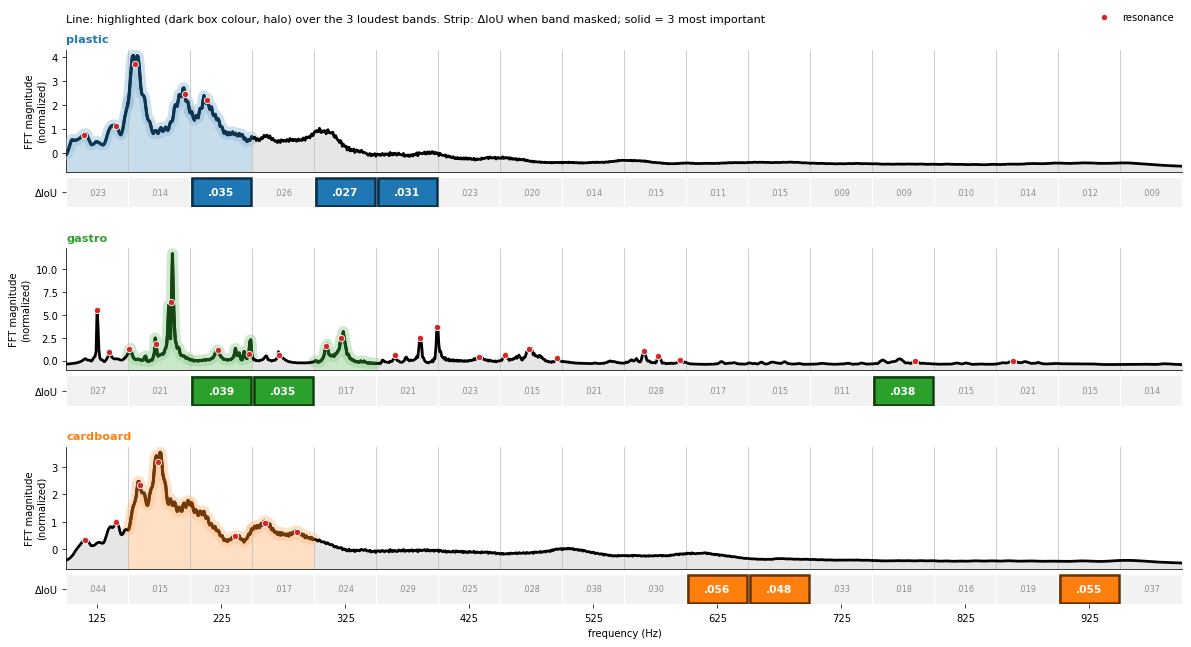

In [8]:
RED = "#d62728"   # resonance dots, same for every box
def loud_line(a, b, lw=2.2, fill=False):   # black line; over the 3 loudest bands a dark box-colour segment on a light halo; optional grey fill (light box tint under the loudest bands)
    z, c = ZS[b], np.array(to_rgb(BOXC[b])); lo = z.min() - .05 * np.ptp(z); a.plot(FHZ, z, c="k", lw=lw, zorder=4)
    if fill:
        a.fill_between(FHZ, lo, z, color="0.9", lw=0, zorder=1)
        for k in LOUD[b]: w = np.nonzero(BIN == k)[0]; w = np.r_[max(w[0] - 1, 0), w]; a.fill_between(FHZ[w], lo, z[w], color=.25 * c + .75, lw=0, zorder=1.5)
    for k in LOUD[b]:
        w = np.nonzero(BIN == k)[0]; w = np.r_[max(w[0] - 1, 0), w, min(w[-1] + 1, 1169)]
        a.plot(FHZ[w], z[w], c=.45 * c + .55, lw=9, alpha=.5, solid_capstyle="round", zorder=3)
        a.plot(FHZ[w], z[w], c=.45 * c, lw=lw + .3, solid_capstyle="butt", zorder=4.5)
    r = RES["train", b]; a.scatter(FHZ[r], z[r], s=26, c=RED, edgecolors="white", linewidths=.7, zorder=5, label="resonance")
def fig_v8():
    gmax = max(M5[b].max() for b in BX)
    with plt.rc_context(PAPER):
        fig = plt.figure(figsize=(16, 8)); gs = fig.add_gridspec(8, 1, height_ratios=[2.2, .55, .55] * 2 + [2.2, .55], hspace=.08)
        for n, b in enumerate(BX):
            a, h = fig.add_subplot(gs[3 * n]), fig.add_subplot(gs[3 * n + 1])
            z = ZS[b]; loud_line(a, b, fill=True)
            for e in 100 + 50 * np.arange(1, 18): a.axvline(e, c="0.75", lw=.6, zorder=2)   # band edges, same as the heatmap cell borders
            a.set_ylim(z.min() - .05 * np.ptp(z), z.max() + .05 * np.ptp(z)); a.set_xlim(100, 1000); a.tick_params(labelbottom=False, bottom=False); a.spines[["top", "right"]].set_visible(False)
            a.set_ylabel("FFT magnitude\n(normalized)"); a.set_title(b, loc="left", fontweight="bold", color=BOXC[b])
            for k in range(18):   # faded cells, top-3 solid box colour with a dark outline
                T = k in TOP[b]; h.add_patch(plt.Rectangle((BC[k] - 25, 0), 50, 1, fc=BOXC[b] if T else "0.95", ec="white", lw=1))
                h.text(BC[k], .5, fmt(M5[b][k]), ha="center", va="center", fontsize=8.5 if T else 6.5, color="white" if T else "0.55", fontweight="bold" if T else "normal")
            for k in TOP[b]: h.add_patch(plt.Rectangle((BC[k] - 24, .04), 48, .92, fill=False, ec=.4 * np.array(to_rgb(BOXC[b])), lw=2, zorder=4))
            h.set_ylim(0, 1)
            h.set_yticks([.5], ["ΔIoU"]); h.set_xlim(100, 1000); xaxis(h, n == 2)
            if n < 2: h.tick_params(bottom=False)
            for sp in h.spines.values(): sp.set_visible(False)
        fig.suptitle("Line: highlighted (dark box colour, halo) over the 3 loudest bands. Strip: ΔIoU when band masked; solid = 3 most important",
                     x=.125, ha="left", fontsize=9, y=.93)
        fig.legend(*a.get_legend_handles_labels(), loc="upper right", bbox_to_anchor=(.9, .945), frameon=False, fontsize=8)
        (Path.cwd() / "plots").mkdir(exist_ok=True); fig.savefig(Path.cwd() / "plots/nb138_v8.pdf", bbox_inches="tight")
        plt.show()
fig_v8()

### V9: split tracks, spectrum over ΔIoU bars, dashed guides at the 3 loudest bands

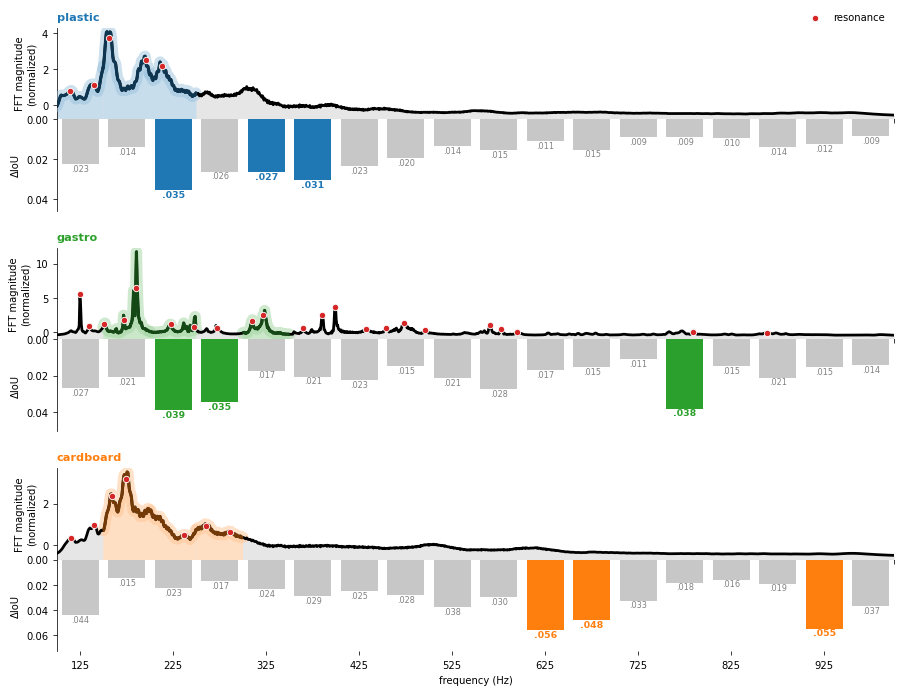

In [22]:
def fig_v9():   # butterfly: spectrum above a shared x-axis line, ΔIoU bars hanging down from it
    with plt.rc_context(PAPER):
        fig = plt.figure(figsize=(12, 9)); gs = fig.add_gridspec(8, 1, height_ratios=[1, 1, .4] * 2 + [1, 1], hspace=0)
        for n, b in enumerate(BX):
            a, t = fig.add_subplot(gs[3 * n]), fig.add_subplot(gs[3 * n + 1])
            z, m = ZS[b], M5[b]; loud_line(a, b, fill=True)
            a.set_ylim(z.min() - .05 * np.ptp(z), z.max() + .05 * np.ptp(z)); a.set_ylabel("FFT magnitude\n(normalized)"); a.set_title(b, loc="left", fontweight="bold", color=BOXC[b])
            a.spines[["top", "right"]].set_visible(False); a.set_xlim(100, 1000); a.tick_params(labelbottom=False)
            t.bar(BC, m, 40, color=[BOXC[b] if k in TOP[b] else GREY for k in range(18)], lw=0)
            for k in range(18): t.text(BC[k], m[k], fmt(m[k]), ha="center", va="top", fontsize=7.5 if k in TOP[b] else 6.5, fontweight="bold" if k in TOP[b] else "normal", color=BOXC[b] if k in TOP[b] else "0.5")
            t.set_ylim(0, 1.3 * m.max()); t.invert_yaxis(); t.set_ylabel("ΔIoU"); t.spines[["top", "right", "bottom"]].set_visible(False); t.set_xlim(100, 1000)
            xaxis(t, n == 2)
            if n < 2: t.tick_params(bottom=False)
        fig.legend(*a.get_legend_handles_labels(), loc="upper right", bbox_to_anchor=(.9, .91), frameon=False, fontsize=8)
        plt.show()
fig_v9()

### V10: polished V5

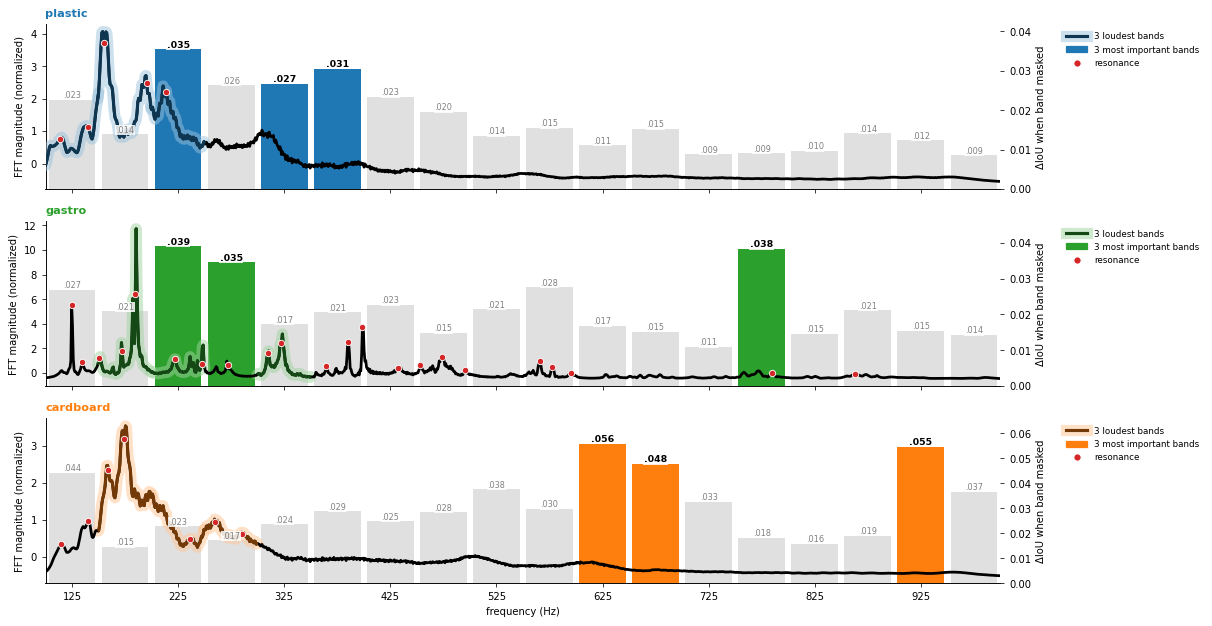

In [23]:
def fig_v10():
    from matplotlib.patches import Patch
    from matplotlib.lines import Line2D
    with plt.rc_context(PAPER):
        fig, ax = plt.subplots(3, 1, figsize=(13.5, 7), sharex=True)
        for n, (a, b) in enumerate(zip(ax, BX)):
            z, m, c = ZS[b], M5[b], np.array(to_rgb(BOXC[b])); t = a.twinx(); a.set_zorder(t.get_zorder() + 1); a.patch.set_visible(False)
            t.bar(BC, m, 44, color=[BOXC[b] if k in TOP[b] else "0.88" for k in range(18)], lw=0)
            for k in range(18):   # drawn on the front axes (in bar coordinates) with a white box, so the line never covers them
                a.text(BC[k], m[k], fmt(m[k]), transform=t.transData, ha="center", va="bottom", zorder=6, fontsize=7.5 if k in TOP[b] else 6.5,
                       fontweight="bold" if k in TOP[b] else "normal", color="k" if k in TOP[b] else "0.5", bbox=dict(fc="white", ec="none", pad=.6, alpha=.85))
            t.set_ylim(0, 1.18 * m.max()); t.set_ylabel("ΔIoU when band masked"); t.spines["top"].set_visible(False); t.spines["right"].set_color("k")
            loud_line(a, b)
            a.set_ylim(z.min() - .05 * np.ptp(z), z.max() + .05 * np.ptp(z)); a.set_ylabel("FFT magnitude (normalized)"); a.spines["top"].set_visible(False)
            a.set_title(b, loc="left", fontweight="bold", color=BOXC[b]); xaxis(a, n == 2)
            a.legend([(Line2D([], [], c=.45 * c + .55, lw=9, alpha=.5), Line2D([], [], c=.45 * c, lw=2.5)), Patch(color=BOXC[b]), Line2D([], [], ls="", marker="o", ms=6, mfc=RED, mec="white")],
                     ["3 loudest bands", "3 most important bands", "resonance"], loc="upper left", bbox_to_anchor=(1.06, 1), fontsize=7, frameon=False, handlelength=2.5)
        fig.tight_layout(); plt.show()
fig_v10()

### V11: one panel per box: loudest bands on the line, most important bands as fill under it (opacity ∝ ΔIoU)

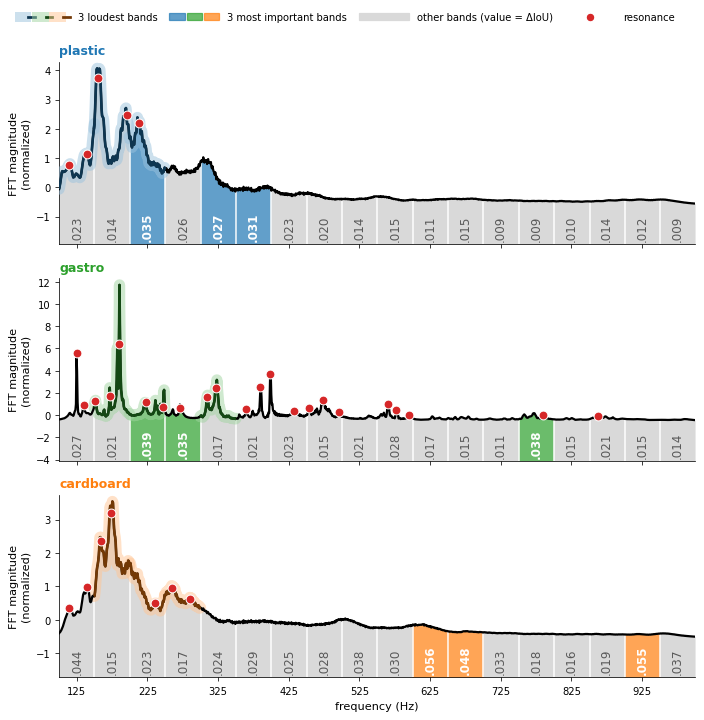

In [9]:
def fig_v11():
    from matplotlib.patches import Patch
    from matplotlib.lines import Line2D
    from matplotlib.legend_handler import HandlerTuple
    with plt.rc_context(PAPER | {"font.size": 9, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8}):
        fig, ax = plt.subplots(3, 1, figsize=(8, 8), sharex=True)
        for n, (a, b) in enumerate(zip(ax, BX)):
            z, m, c = ZS[b], M5[b], np.array(to_rgb(BOXC[b])); lo, hi = z.min() - .3 * np.ptp(z), z.max() + .05 * np.ptp(z)   # bottom margin holds the (vertical) values
            for k in range(18):   # one "bar" per band: fill from the axis bottom up to the line, value at its foot (rotated 90°)
                T = k in TOP[b]; w = np.nonzero(BIN == k)[0]; w = np.r_[max(w[0] - 1, 0), w, min(w[-1] + 1, 1169)]
                a.fill_between(FHZ[w], lo, z[w], color=BOXC[b] if T else "0.85", alpha=.7 if T else 1, lw=0, zorder=1)
                a.text(BC[k], lo + .02 * np.ptp(z), fmt(m[k]), ha="center", va="bottom", rotation=90, zorder=6, fontsize=9.5,
                       fontweight="bold" if T else "normal", color="white" if T else "0.35")
            for e in 100 + 900 * np.arange(1, 18) * 65 / 1169: a.axvline(e, c="white", lw=1.2, zorder=2)   # white gaps at the band edges
            loud_line(a, b, lw=1.8); r = RES["train", b]; a.scatter(FHZ[r], z[r], s=50, c=RED, edgecolors="white", linewidths=.8, zorder=5.5)
            a.set_ylim(lo, hi); a.set_ylabel("FFT magnitude\n(normalized)"); a.spines[["top", "right"]].set_visible(False)
            a.set_title(b, loc="left", fontweight="bold", color=BOXC[b], fontsize=10); xaxis(a, n == 2)
        C3 = [np.array(to_rgb(BOXC[b])) for b in BX]
        H = [tuple((Line2D([], [], c=.45 * c + .55, lw=8, alpha=.5), Line2D([], [], c=.45 * c, lw=2.2)) for c in C3),
             tuple(Patch(color=BOXC[b], alpha=.7) for b in BX), Patch(color="0.85"), Line2D([], [], ls="", marker="o", ms=7, mfc=RED, mec="white")]
        fig.legend(H, ["3 loudest bands", "3 most important bands", "other bands (value = ΔIoU)", "resonance"], loc="upper center", ncol=4, frameon=False, fontsize=8,
                   handler_map={tuple: HandlerTuple(ndivide=None, pad=.2)}, handlelength=5, columnspacing=1.2, bbox_to_anchor=(.5, 1.0))
        fig.tight_layout(rect=(0, 0, 1, .96)); plt.show()
fig_v11()

### V12: height = loudness, ink = importance: smooth gradient line (width and darkness ∝ ΔIoU)

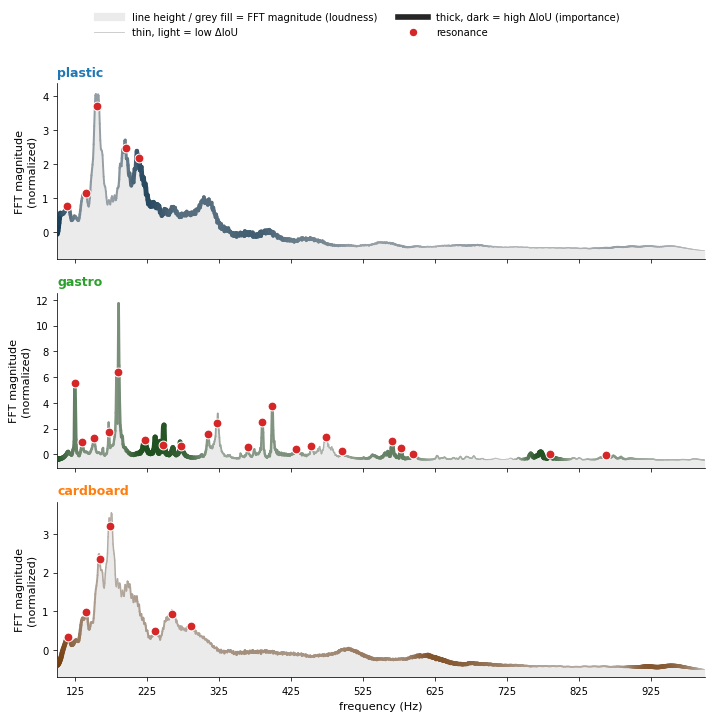

In [9]:
from scipy.interpolate import PchipInterpolator
from scipy import ndimage
from matplotlib.collections import LineCollection
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
WS = {}   # importance along frequency: PCHIP through the 18 band ΔIoU values at the band centres, clipped ≥ 0, then min-max per box (÷ max alone left the least important band at w ≈ .25, too little contrast)
for b in BX: v = np.clip(PchipInterpolator(HZ, M5[b], extrapolate=True)(FHZ), 0, None); WS[b] = (v - v.min()) / np.ptp(v)
SEG = lambda z: np.stack([np.c_[FHZ[:-1], z[:-1]], np.c_[FHZ[1:], z[1:]]], 1)          # (n-1, 2, 2) line segments
mid = lambda v: (v[:-1] + v[1:]) / 2
P8 = PAPER | {"font.size": 9, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8}
def rows8(name, H, L, draw, ncol=2):   # shared frame: 3 rows, (8, 8), titles, dots, Hz on the bottom row, figure legend, PDF
    with plt.rc_context(P8):
        fig, ax = plt.subplots(3, 1, figsize=(8, 8), sharex=True)
        for n, (a, b) in enumerate(zip(ax, BX)):
            z = ZS[b]; a.set_ylim(z.min() - .05 * np.ptp(z), z.max() + .07 * np.ptp(z)); draw(a, b, z, WS[b], np.array(to_rgb(BOXC[b])))
            r = RES["train", b]; a.scatter(FHZ[r], z[r], s=50, c=RED, edgecolors="white", linewidths=.8, zorder=6)
            a.set_ylabel("FFT magnitude\n(normalized)"); a.spines[["top", "right"]].set_visible(False)
            a.set_title(b, loc="left", fontweight="bold", color=BOXC[b], fontsize=10); xaxis(a, n == 2)
        fig.legend(H + [Line2D([], [], ls="", marker="o", ms=7, mfc=RED, mec="white")], L + ["resonance"], loc="upper center", ncol=ncol, frameon=False, fontsize=8, handlelength=3, bbox_to_anchor=(.5, 1))
        fig.tight_layout(rect=(0, 0, 1, .93)); (Path.cwd() / "plots").mkdir(exist_ok=True); fig.savefig(Path.cwd() / f"plots/{name}.pdf", bbox_inches="tight"); plt.show()
def draw_v12(a, b, z, w, c):
    a.fill_between(FHZ, a.get_ylim()[0], z, color="0.92", lw=0, zorder=1)
    wm = mid(w); col = (1 - wm[:, None]) * np.array([.75, .75, .75]) + wm[:, None] * .45 * c
    a.add_collection(LineCollection(SEG(z), linewidths=.6 + 3.9 * wm, colors=col, capstyle="round", zorder=4))
def fig_v12():
    rows8("nb138_v12", [Patch(color="0.92"), Line2D([], [], c="0.75", lw=.6), Line2D([], [], c="0.15", lw=4.5)],
          ["line height / grey fill = FFT magnitude (loudness)", "thin, light = low ΔIoU", "thick, dark = high ΔIoU (importance)"], draw_v12)
fig_v12()

### V13: height = loudness, ink = importance: variable-width ribbon (half-width ∝ ΔIoU)

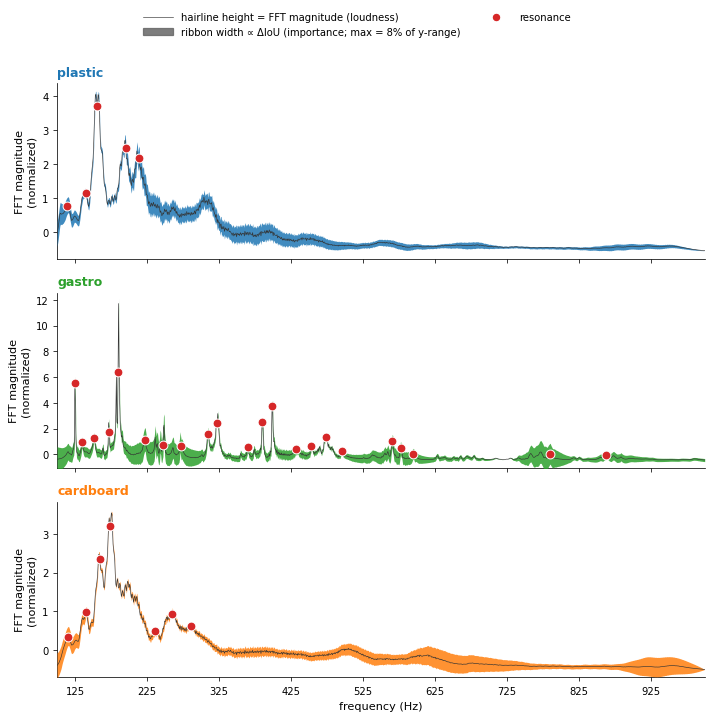

In [10]:
H13 = .08   # ribbon half-width at max ΔIoU = 8% of the box's y-range
def draw_v13(a, b, z, w, c):
    h = H13 * np.ptp(z); a.fill_between(FHZ, z - h * w, z + h * w, color=BOXC[b], alpha=.85, lw=0, zorder=3)
    a.plot(FHZ, z, c="0.2", lw=.5, zorder=4)
def fig_v13():
    rows8("nb138_v13", [Line2D([], [], c="0.2", lw=.5), Patch(color="0.4", alpha=.85)],
          ["hairline height = FFT magnitude (loudness)", f"ribbon width ∝ ΔIoU (importance; max = {H13:.0%} of y-range)"], draw_v13)
fig_v13()

### V14: height = loudness, ink = importance: crisp line with an importance glow

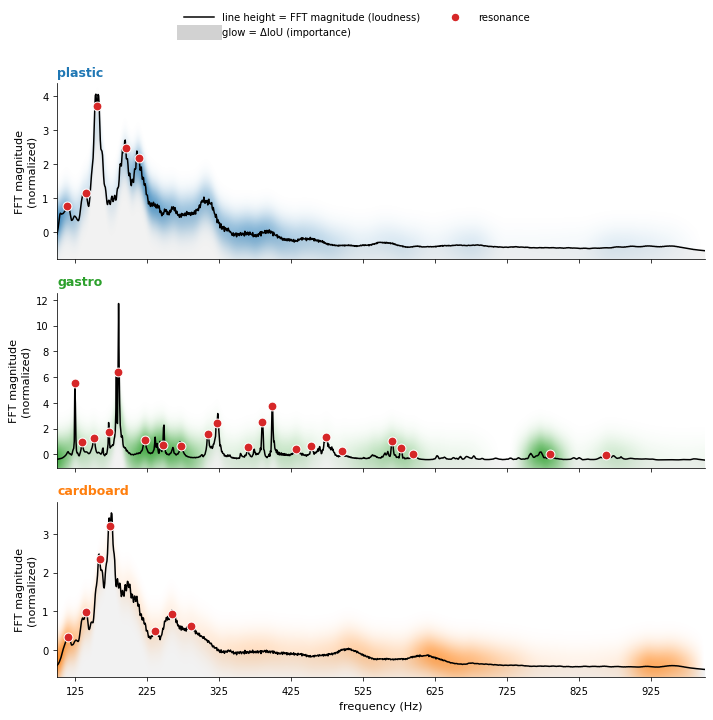

In [11]:
def draw_v14(a, b, z, w, c):   # glow = RGBA image: alpha(x, y) = w(x) · exp(-(y - z(x))² / 2s²), s = 8% of the y-range, centred on a lightly smoothed line (no overlapping strokes, so no alpha pile-up)
    a.fill_between(FHZ, a.get_ylim()[0], z, color="0.95", lw=0, zorder=1)
    y0, y1 = a.get_ylim(); Y = np.linspace(y0, y1, 400)[:, None]; s_ = .08 * (y1 - y0); zs = ndimage.gaussian_filter1d(z, 6)
    G = np.zeros((400, len(FHZ), 4)); G[..., :3] = c; G[..., 3] = .9 * w[None] ** 1.3 * np.exp(-(Y - zs[None]) ** 2 / (2 * s_ ** 2))
    a.imshow(G, extent=(FHZ[0], FHZ[-1], y0, y1), origin="lower", aspect="auto", interpolation="bilinear", zorder=2)
    a.plot(FHZ, z, c="k", lw=1.2, zorder=4)
def fig_v14():
    rows8("nb138_v14", [Line2D([], [], c="k", lw=1.2), Line2D([], [], c="0.5", lw=12, alpha=.35)],
          ["line height = FFT magnitude (loudness)", "glow = ΔIoU (importance)"], draw_v14)
fig_v14()

### V15: height = loudness, hatch density = importance (ΔIoU in 5 levels per box, top 3 densest)

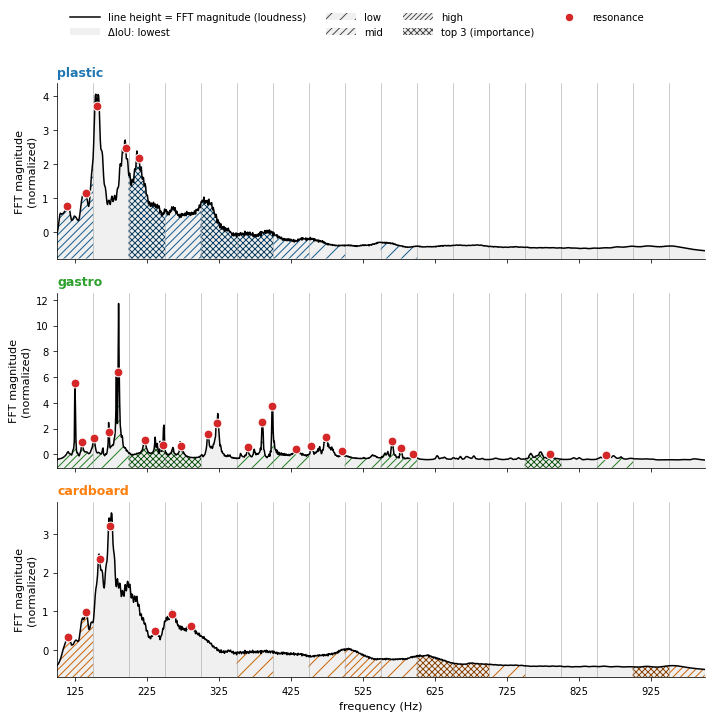

In [10]:
HATCH = ["", "//", "////", "//////", "xxxxx"]   # level 0 (least important) → 4 (top 3)
def levels(b):   # bands min-max scaled into levels 0..3, the top-3 bands forced to level 4
    m = M5[b]; q = np.clip(np.floor(4 * (m - m.min()) / np.ptp(m)), 0, 3).astype(int); q[TOP[b]] = 4; return q
def draw_v15(a, b, z, w, c):
    lo, q = a.get_ylim()[0], levels(b); a.fill_between(FHZ, lo, z, color="0.94", lw=0, zorder=1)
    for k in range(18):
        ix = np.nonzero(BIN == k)[0]; ix = np.r_[max(ix[0] - 1, 0), ix, min(ix[-1] + 1, 1169)]
        if q[k]: a.fill_between(FHZ[ix], lo, z[ix], facecolor="none", edgecolor=.8 * c if q[k] < 4 else .55 * c, hatch=HATCH[q[k]], lw=0, zorder=2)
    for e in 100 + 50 * np.arange(1, 18): a.axvline(e, c="0.6", lw=.4, zorder=3)
    a.plot(FHZ, z, c="k", lw=1.2, zorder=4)
def fig_v15():
    with plt.rc_context({"hatch.linewidth": .8}):
        H = [Patch(facecolor="0.94", edgecolor="0.3", hatch=h, lw=0) for h in HATCH]
        rows8("nb138_v15", [Line2D([], [], c="k", lw=1.2)] + H,
              ["line height = FFT magnitude (loudness)", "ΔIoU: lowest", "low", "mid", "high", "top 3 (importance)"], draw_v15, ncol=4)
fig_v15()

### V16: height = loudness, band around the line = importance (width & colour ∝ ΔIoU; per-box min-max scaled, as in V12–V14)

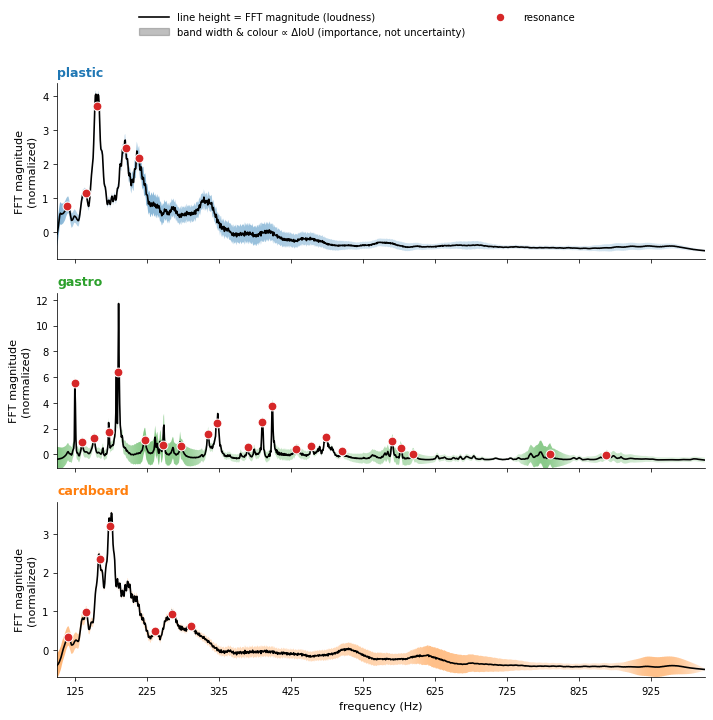

In [11]:
H16 = .08   # half-width at max importance = 8% of the box's y-range (as V13)
def draw_v16(a, b, z, w, c):   # band = fill_between polygon used as a clip path for an RGBA image whose alpha varies along x (.1 → .6 with w)
    hw = H16 * np.ptp(z) * (.08 + .92 * w)                                            # thin ring even where w = 0
    poly = a.fill_between(FHZ, z - hw, z + hw, color="none", lw=0)
    y0, y1 = a.get_ylim(); G = np.zeros((2, len(FHZ), 4)); G[..., :3] = c; G[..., 3] = .1 + .5 * w[None]
    im = a.imshow(G, extent=(FHZ[0], FHZ[-1], y0, y1), origin="lower", aspect="auto", interpolation="bilinear", zorder=2); im.set_clip_path(poly.get_paths()[0], transform=a.transData)
    a.set_ylim(y0, y1); a.plot(FHZ, z, c="k", lw=1.3, zorder=4)
def fig_v16():
    rows8("nb138_v16", [Line2D([], [], c="k", lw=1.3), Patch(color="0.45", alpha=.45)],
          ["line height = FFT magnitude (loudness)", "band width & colour ∝ ΔIoU (importance, not uncertainty)"], draw_v16)
fig_v16()